# 02 – Unsupervised Learning

## 1. Introduction

Unsupervised learning is a machine learning approach that discovers hidden patterns, structures and similarities in data without using predefined class labels during model training.

In this project, unsupervised learning is used to investigate whether plant leaf images naturally form meaningful groups based on their visual characteristics.

## 2. Objectives

- Explore the structure of handcrafted image representations.
- Reduce feature dimensionality using Principal Component Analysis (PCA).
- Discover natural clusters using K-Means clustering.
- Explore probabilistic clustering using Gaussian Mixture Models (GMM).
- Evaluate clustering quality using Silhouette Score, Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI).
- Visualize the discovered clusters.

## 3. Feature Representations

The following handcrafted feature representations will be investigated:

1. Histogram of Oriented Gradients (HOG)
2. Hue, Saturation and Value (HSV)
3. Local Binary Patterns (LBP)
4. Combined HOG + HSV + LBP features

Disease labels will not be provided to PCA, K-Means or GMM during fitting. They will only be used after clustering for evaluation and interpretation.

In [3]:
# Numerical operations
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dimensionality reduction
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Clustering algorithms
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

# Evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Utility libraries
import os
import warnings
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import IncrementalPCA


# Import the libraries required for the improved GMM experiment
import time
import warnings
import gc
import numpy as np
import pandas as pd

# Import the GMM model and convergence warning
from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning

# Import clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

print("All required libraries imported successfully!")


warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All required libraries imported successfully!
All libraries imported successfully!


In [4]:
print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders:")
for item in Path.cwd().iterdir():
    print(item.name)

Current working directory:
/workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/notebooks

Files and folders:
inspect_dataset.ipynb
02_Un_supervised_learning.ipynb
README.md
01_supervised_learning.ipynb


In [5]:
# Project root: parent of notebooks directory
PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)
print("\nChecking feature cache directories:")

cache_folders = [
    "data/hog_cache",
    "data/hsv_cache",
    "data/lbp_cache"
]

for folder in cache_folders:
    path = PROJECT_ROOT / folder
    print(f"\n{folder}:")

    if path.exists():
        print("Available")
        for file in path.iterdir():
            if file.is_file():
                print(f"  {file.name} - {file.stat().st_size / (1024**2):.2f} MB")
    else:
        print("Not found")

Project root: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection

Checking feature cache directories:

data/hog_cache:
Available
  test_features.npy - 162.93 MB
  train_labels.npy - 4.23 MB
  train_features.npy - 761.04 MB
  test_labels_original_pipeline.npy - 0.91 MB
  valid_labels.npy - 0.91 MB
  valid_features.npy - 163.09 MB
  test_labels.npy - 0.91 MB
  test_features_original_pipeline.npy - 162.93 MB

data/hsv_cache:
Available
  train_labels.npy - 4.23 MB
  test_labels.npy - 0.91 MB
  valid_features.npy - 10.31 MB
  test_features.npy - 10.30 MB
  test_features_original_pipeline.npy - 10.30 MB
  valid_labels.npy - 0.91 MB
  train_features.npy - 48.11 MB

data/lbp_cache:
Available
  test_features.npy - 0.20 MB
  train_labels.npy - 4.23 MB
  test_features_original_pipeline.npy - 0.20 MB
  train_features.npy - 0.94 MB
  valid_features.npy - 0.20 MB
  test_labels.npy - 0.91 MB
  valid_labels.npy - 0.91 MB


In [6]:
import torch
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("CUDA is not available in this Python environment.")

PyTorch version: 2.15.0+cu134
CUDA available: True
GPU: NVIDIA GB10
CUDA version: 13.4


Loading and Inspecting Training Feature Representations
The existing HOG, HSV and LBP feature representations will be loaded from the project's cache directories.

Only training features will be used to fit unsupervised learning transformations and clustering models. Disease labels will be retained for evaluation after clustering.

In [6]:
# Project directory
PROJECT_ROOT = Path.cwd().parent

# Load training features
X_train_hog = np.load(
    PROJECT_ROOT / "data/hog_cache/train_features.npy",
    mmap_mode="r"
)

X_train_hsv = np.load(
    PROJECT_ROOT / "data/hsv_cache/train_features.npy",
    mmap_mode="r"
)

X_train_lbp = np.load(
    PROJECT_ROOT / "data/lbp_cache/train_features.npy",
    mmap_mode="r"
)

# Load labels from each feature cache
y_train_hog = np.load(
    PROJECT_ROOT / "data/hog_cache/train_labels.npy"
)

y_train_hsv = np.load(
    PROJECT_ROOT / "data/hsv_cache/train_labels.npy"
)

y_train_lbp = np.load(
    PROJECT_ROOT / "data/lbp_cache/train_labels.npy"
)

print("FEATURES LOADED SUCCESSFULLY!")

FEATURES LOADED SUCCESSFULLY!


In [8]:
## Inspect dimensions
feature_data = {
    "HOG": X_train_hog,
    "HSV": X_train_hsv,
    "LBP": X_train_lbp
}

print("TRAINING FEATURE DIMENSIONS")
print("-" * 50)

for name, features in feature_data.items():
    print(f"{name}:")
    print("  Shape:", features.shape)
    print("  Data type:", features.dtype)
    print("  Samples:", features.shape[0])
    print("  Features:", features.shape[1])

print("\nTraining labels:", y_train_hog.shape)
print("Unique disease classes:", len(np.unique(y_train_hog)))

TRAINING FEATURE DIMENSIONS
--------------------------------------------------
HOG:
  Shape: (24630, 8100)
  Data type: float32
  Samples: 24630
  Features: 8100
HSV:
  Shape: (24630, 512)
  Data type: float32
  Samples: 24630
  Features: 512
LBP:
  Shape: (24630, 10)
  Data type: float32
  Samples: 24630
  Features: 10

Training labels: (24630,)
Unique disease classes: 19


In [10]:
## Verify label alignment
assert np.array_equal(y_train_hog, y_train_hsv), \
    "HOG and HSV labels do not match!"

assert np.array_equal(y_train_hog, y_train_lbp), \
    "HOG and LBP labels do not match!"

assert len(X_train_hog) == len(y_train_hog)
assert len(X_train_hsv) == len(y_train_hsv)
assert len(X_train_lbp) == len(y_train_lbp)

print("All three feature representations are aligned!")
print("All training labels match.")

All three feature representations are aligned!
All training labels match.


In [11]:
#Check missing and infinite values
def check_feature_values(name, features, chunk_size=2000):
    nan_count = 0
    inf_count = 0

    for start in range(0, features.shape[0], chunk_size):
        batch = np.asarray(
            features[start:start + chunk_size]
        )

        nan_count += np.isnan(batch).sum()
        inf_count += np.isinf(batch).sum()

    print(f"\n{name}")
    print("NaN values:", nan_count)
    print("Infinite values:", inf_count)

for name, features in feature_data.items():
    check_feature_values(name, features)


HOG
NaN values: 0
Infinite values: 0

HSV
NaN values: 0
Infinite values: 0

LBP
NaN values: 0
Infinite values: 0


## 7. Feature Distribution Analysis
##### Before applying dimensionality reduction, we examine the numerical distributions of HOG, HSV and LBP features.

##### This analysis helps determine whether feature standardization or another scaling strategy is appropriate. It also helps identify differences between individual and combined feature representations.

In [12]:
def analyse_feature_distribution(name, features, chunk_size=1000):

    n_samples, n_features = features.shape

    global_min = np.inf
    global_max = -np.inf
    total_sum = 0.0
    total_sq_sum = 0.0
    zero_count = 0
    row_norm_sum = 0.0
    feature_sum = np.zeros(n_features, dtype=np.float64)
    feature_sq_sum = np.zeros(n_features, dtype=np.float64)

    total_values = n_samples * n_features

    for start in range(0, n_samples, chunk_size):

        batch = np.asarray(
            features[start:start + chunk_size],
            dtype=np.float64
        )

        global_min = min(global_min, batch.min())
        global_max = max(global_max, batch.max())

        total_sum += batch.sum()
        total_sq_sum += np.square(batch).sum()

        zero_count += np.count_nonzero(batch == 0)

        feature_sum += batch.sum(axis=0)
        feature_sq_sum += np.square(batch).sum(axis=0)

        row_norm_sum += np.linalg.norm(
            batch, axis=1
        ).sum()

    global_mean = total_sum / total_values

    global_variance = (
        total_sq_sum / total_values - global_mean**2
    )

    global_std = np.sqrt(max(global_variance, 0))

    feature_means = feature_sum / n_samples

    feature_variances = (
        feature_sq_sum / n_samples - feature_means**2
    )

    feature_stds = np.sqrt(
        np.maximum(feature_variances, 0)
    )

    print(f"\n{'=' * 55}")
    print(f"{name} FEATURE DISTRIBUTION")
    print("=" * 55)

    print(f"Minimum value: {global_min:.6f}")
    print(f"Maximum value: {global_max:.6f}")
    print(f"Global mean: {global_mean:.6f}")
    print(f"Global standard deviation: {global_std:.6f}")
    print(f"Average feature standard deviation: {feature_stds.mean():.6f}")
    print(f"Zero values: {zero_count / total_values * 100:.2f}%")
    print(f"Average L2 norm: {row_norm_sum / n_samples:.6f}")

    return {
        "Feature": name,
        "Minimum": global_min,
        "Maximum": global_max,
        "Mean": global_mean,
        "Global Std": global_std,
        "Average Feature Std": feature_stds.mean(),
        "Zero Percentage": zero_count / total_values * 100,
        "Average L2 Norm": row_norm_sum / n_samples
    }


distribution_results = []

for name, features in feature_data.items():

    result = analyse_feature_distribution(name, features)
    distribution_results.append(result)

distribution_df = pd.DataFrame(distribution_results)

print("\nSUMMARY")
display(distribution_df.round(6))


HOG FEATURE DISTRIBUTION
Minimum value: 0.000000
Maximum value: 1.000000
Global mean: 0.139326
Global standard deviation: 0.091078
Average feature standard deviation: 0.088830
Zero values: 2.50%
Average L2 norm: 14.979322

HSV FEATURE DISTRIBUTION
Minimum value: 0.000000
Maximum value: 0.999481
Global mean: 0.007236
Global standard deviation: 0.043598
Average feature standard deviation: 0.022255
Zero values: 68.75%
Average L2 norm: 1.000000

LBP FEATURE DISTRIBUTION
Minimum value: 0.001465
Maximum value: 0.890701
Global mean: 0.100000
Global standard deviation: 0.058213
Average feature standard deviation: 0.042789
Zero values: 0.00%
Average L2 norm: 0.363694

SUMMARY


,Feature,Minimum,Maximum,Mean,Global Std,Average Feature Std,Zero Percentage,Average L2 Norm
0,HOG,0.000000,1.000000,0.139326,0.091078,0.088830,2.502732,14.979322
1,HSV,0.000000,0.999481,0.007236,0.043598,0.022255,68.751166,1.000000
2,LBP,0.001465,0.890701,0.100000,0.058213,0.042789,0.000000,0.363694


### 8. Principal Component Analysis (PCA)

Principal Component Analysis is an unsupervised dimensionality reduction technique that transforms high-dimensional data into a smaller set of uncorrelated variables called principal components.

In this project, PCA is applied to HOG, HSV, LBP and combined feature representations to:

- Reduce computational complexity.
- Identify the most informative directions of variation.
- Study how much information can be retained with fewer dimensions.
- Visualize the feature representations in two dimensions.

The number of retained components will be investigated using explained variance, with 95% cumulative explained variance as an initial target.

In [17]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize LBP features
lbp_scaler = StandardScaler()

X_train_lbp_scaled = lbp_scaler.fit_transform(
    np.asarray(X_train_lbp)
)

# Fit PCA with 10 components
lbp_pca = PCA(
    n_components=10,
    svd_solver="full"
)

X_pca_lbp = lbp_pca.fit_transform(
    X_train_lbp_scaled
)

# Calculate explained variance
lbp_variance = lbp_pca.explained_variance_ratio_
lbp_cumulative = np.cumsum(lbp_variance)

print("Original dimensions:", X_train_lbp.shape[1])
print("Reduced dimensions:", X_pca_lbp.shape[1])

print("\nExplained variance:")
for i, variance in enumerate(lbp_variance):
    print(
        f"PC{i+1}: {variance*100:.2f}% "
        f"| Cumulative: {lbp_cumulative[i]*100:.2f}%"
    )

Original dimensions: 10
Reduced dimensions: 10

Explained variance:
PC1: 74.34% | Cumulative: 74.34%
PC2: 18.16% | Cumulative: 92.49%
PC3: 4.40% | Cumulative: 96.89%
PC4: 1.78% | Cumulative: 98.67%
PC5: 0.57% | Cumulative: 99.25%
PC6: 0.31% | Cumulative: 99.56%
PC7: 0.25% | Cumulative: 99.81%
PC8: 0.16% | Cumulative: 99.97%
PC9: 0.03% | Cumulative: 100.00%
PC10: 0.00% | Cumulative: 100.00%


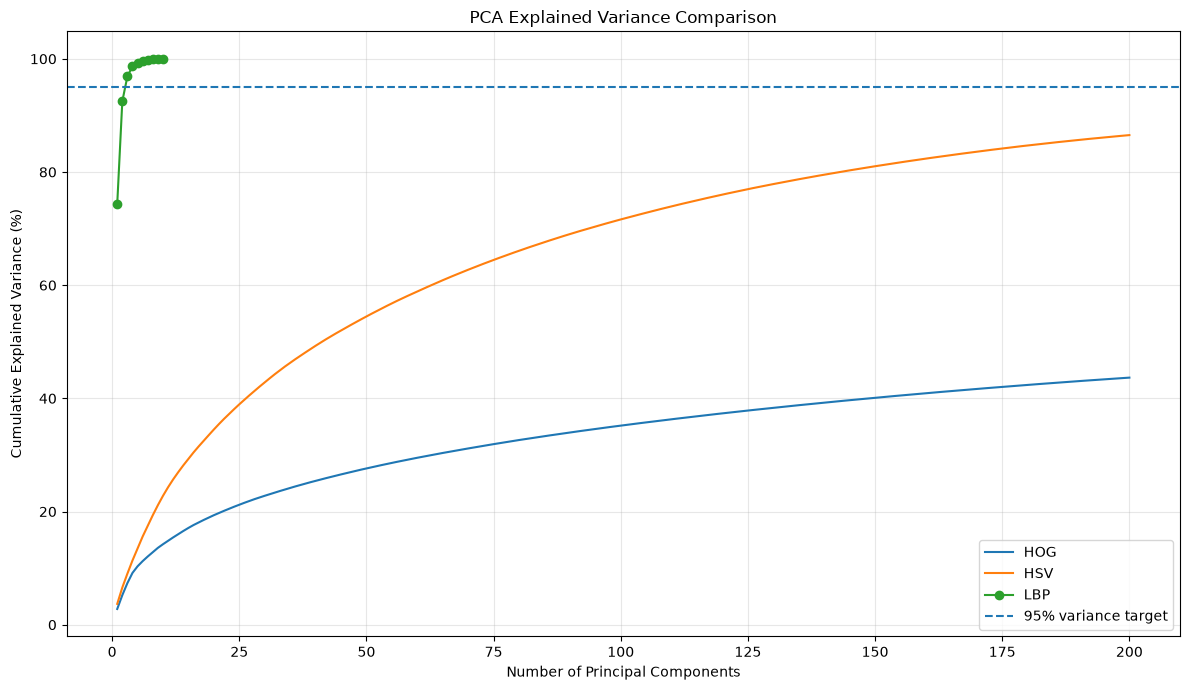

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.plot(
    np.arange(1, 201),
    pca_results["HOG"]["cumulative_variance"] * 100,
    label="HOG"
)

plt.plot(
    np.arange(1, 201),
    pca_results["HSV"]["cumulative_variance"] * 100,
    label="HSV"
)

plt.plot(
    np.arange(1, 11),
    lbp_cumulative * 100,
    marker="o",
    label="LBP"
)

plt.axhline(
    y=95,
    linestyle="--",
    label="95% variance target"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Explained Variance Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

try:
    import cuml
    print("cuML version:", cuml.__version__)
    print("GPU-accelerated PCA is available.")

except ImportError:
    print("cuML is not installed.")

CUDA available: True
GPU: NVIDIA GB10
cuML is not installed.


### 11. GPU-Accelerated Principal Component Analysis
PyTorch CUDA is used to perform randomized singular value decomposition for dimensionality reduction.

The experiments will:
- Standardize individual feature representations.
- Perform PCA using the NVIDIA GPU.
- Estimate cumulative explained variance.
- Identify the number of components required to approach 95% variance retention.
- Preserve the resulting representations for subsequent clustering experiments.

In [23]:
import torch
import gc
import time

# GPU configuration
DEVICE = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print("Device:", DEVICE)

PCA_VARIANCE_TARGET = 0.95
PCA_INITIAL_COMPONENTS = 512
PCA_OVERSAMPLES = 32
PCA_ITERATIONS = 5

gpu_pca_results = {}


def run_gpu_pca(name, features, initial_components=512):

    print(f"\n{'='*55}")
    print(f"GPU PCA: {name}")
    print("="*55)

    start_time = time.time()

    # Move one feature matrix to GPU
    X = torch.as_tensor(
        np.asarray(features),
        dtype=torch.float32,
        device=DEVICE
    )

    n_samples, n_features = X.shape

    # Standardize using training data only
    mean = X.mean(dim=0)
    std = X.std(dim=0, unbiased=True)

    std = torch.where(std > 1e-8, std, 1.0)

    X_scaled = (X - mean) / std

    # Total variance across all standardized features
    total_variance = torch.sum(
        X_scaled ** 2
    ) / (n_samples - 1)

    # Determine initial number of components
    q = min(
        initial_components,
        n_features,
        n_samples - 1
    )

    # Randomized PCA using GPU
    U, S, V = torch.pca_lowrank(
        X_scaled,
        q=q,
        center=False,
        niter=PCA_ITERATIONS
    )

    explained_variance = (S ** 2) / (n_samples - 1)

    explained_ratio = explained_variance / total_variance

    cumulative_variance = torch.cumsum(explained_ratio, dim=0)

    # Find components needed for 95% variance, if reached
    reached_target = bool(
        cumulative_variance[-1] >= PCA_VARIANCE_TARGET
    )

    retained_components = None

    if reached_target:
        retained_components = int(
            torch.searchsorted(
                cumulative_variance,
                PCA_VARIANCE_TARGET
            ).item()
        ) + 1

    # Transform training data
    X_reduced = U * S.unsqueeze(0)

    elapsed = time.time() - start_time

    print("Original dimensions:", n_features)
    print("Components calculated:", q)
    print(
        "Variance retained:",
        f"{cumulative_variance[-1].item()*100:.2f}%"
    )

    if retained_components is not None:
        print("Components needed for 95%:", retained_components)
    else:
        print("95% target not reached; more components are required.")

    print(f"Execution time: {elapsed:.2f} seconds")

    # Store outputs on CPU to free GPU memory
    gpu_pca_results[name] = {
        "features": X_reduced.cpu().numpy(),
        "mean": mean.cpu().numpy(),
        "std": std.cpu().numpy(),
        "components": V.cpu().numpy(),
        "explained_variance_ratio": explained_ratio.cpu().numpy(),
        "cumulative_variance": cumulative_variance.cpu().numpy(),
        "retained_components": retained_components,
        "total_components": q
    }

    del X, X_scaled, U, S, V
    del mean, std, X_reduced
    gc.collect()
    torch.cuda.empty_cache()

    return gpu_pca_results[name]


# Run one representation at a time
hog_gpu_result = run_gpu_pca(
    "HOG", X_train_hog, 512
)

hsv_gpu_result = run_gpu_pca(
    "HSV", X_train_hsv, 512
)

lbp_gpu_result = run_gpu_pca(
    "LBP", X_train_lbp, 10
)

GPU: NVIDIA GB10
Device: cuda

GPU PCA: HOG
Original dimensions: 8100
Components calculated: 512
Variance retained: 62.24%
95% target not reached; more components are required.
Execution time: 1.99 seconds

GPU PCA: HSV
Original dimensions: 512
Components calculated: 512
Variance retained: 100.01%
Components needed for 95%: 277
Execution time: 0.38 seconds

GPU PCA: LBP
Original dimensions: 10
Components calculated: 10
Variance retained: 100.00%
Components needed for 95%: 3
Execution time: 0.10 seconds


In [24]:
# Extend HOG PCA to 1024 components
hog_gpu_result_1024 = run_gpu_pca(
    "HOG_1024",
    X_train_hog,
    initial_components=1024
)


GPU PCA: HOG_1024
Original dimensions: 8100
Components calculated: 1024
Variance retained: 77.91%
95% target not reached; more components are required.
Execution time: 1.84 seconds


In [25]:
import json

PCA_RESULTS_DIR = (
    PROJECT_ROOT / "results" / "unsupervised_learning" / "pca"
)

PCA_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

summary = {}

for name, result in gpu_pca_results.items():

    summary[name] = {
        "original_dimensions": (
            8100 if "HOG" in name else
            512 if "HSV" in name else
            10
        ),
        "components_calculated": result["total_components"],
        "variance_retained_percent": float(
            result["cumulative_variance"][-1] * 100
        ),
        "components_for_95_percent": (
            result["retained_components"]
        )
    }

with open(PCA_RESULTS_DIR / "gpu_pca_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("PCA summary saved:", PCA_RESULTS_DIR)

PCA summary saved: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/pca


In [28]:
pca_summary = []

for name, result in gpu_pca_results.items():

    pca_summary.append({
        "Representation": name,
        "Components": result["total_components"],
        "Variance Retained (%)": round(
            result["cumulative_variance"][-1] * 100, 2
        ),
        "Components for 95%": result["retained_components"]
    })

pca_summary_df = pd.DataFrame(pca_summary)

display(pca_summary_df)

,Representation,Components,Variance Retained (%),Components for 95%
0,HOG,512,62.240002,NaN
1,HSV,512,100.010002,277.0
2,LBP,10,100.000000,3.0
3,HOG_1024,1024,77.900002,NaN


In [29]:
## increase HOG PCA to 2048 components
hog_gpu_result_2048 = run_gpu_pca(
    name="HOG_2048",
    features=X_train_hog,
    initial_components=2048
)


GPU PCA: HOG_2048
Original dimensions: 8100
Components calculated: 2048
Variance retained: 95.04%
Components needed for 95%: 2044
Execution time: 5.66 seconds


In [30]:
pca_summary = []

for name, result in gpu_pca_results.items():
    pca_summary.append({
        "Representation": name,
        "Original Dimensions": (
            8100 if name.startswith("HOG")
            else 512 if name.startswith("HSV")
            else 10
        ),
        "Components": result["total_components"],
        "Variance Retained (%)": round(
            min(result["cumulative_variance"][-1] * 100, 100), 2
        ),
        "Components for 95%": result["retained_components"]
    })

pca_summary_df = pd.DataFrame(pca_summary)
display(pca_summary_df)

,Representation,Original Dimensions,Components,Variance Retained (%),Components for 95%
0,HOG,8100,512,62.240002,NaN
1,HSV,512,512,100.000000,277.0
2,LBP,10,10,100.000000,3.0
3,HOG_1024,8100,1024,77.900002,NaN
4,HOG_2048,8100,2048,95.040001,2044.0


In [31]:
def transform_with_gpu_pca(features, pca_result, n_components, batch_size=2048):
    """
    Project features using the PCA parameters fitted on training data.
    Works in batches to control GPU memory usage.
    """
    mean = torch.tensor(
        pca_result["mean"], dtype=torch.float32, device=DEVICE
    )
    std = torch.tensor(
        pca_result["std"], dtype=torch.float32, device=DEVICE
    )
    components = torch.tensor(
        pca_result["components"][:, :n_components],
        dtype=torch.float32,
        device=DEVICE
    )

    transformed_batches = []

    for start in range(0, len(features), batch_size):
        end = min(start + batch_size, len(features))

        X_batch = torch.as_tensor(
            np.asarray(features[start:end]),
            dtype=torch.float32,
            device=DEVICE
        )

        X_scaled = (X_batch - mean) / std
        X_projected = X_scaled @ components

        transformed_batches.append(X_projected.cpu().numpy())

        del X_batch, X_scaled, X_projected

    del mean, std, components
    torch.cuda.empty_cache()

    return np.concatenate(transformed_batches, axis=0)

In [33]:
X_valid_hog = np.load(
    PROJECT_ROOT / "data/hog_cache/valid_features.npy",
    mmap_mode="r"
)

In [34]:
#Prepare HOG training and validation data

HOG_PCA_COMPONENTS = 2044

X_train_hog_pca = transform_with_gpu_pca(
    X_train_hog,
    gpu_pca_results["HOG_2048"],
    HOG_PCA_COMPONENTS
)

X_valid_hog_pca = transform_with_gpu_pca(
    X_valid_hog,
    gpu_pca_results["HOG_2048"],
    HOG_PCA_COMPONENTS
)

print("HOG PCA train:", X_train_hog_pca.shape)
print("HOG PCA validation:", X_valid_hog_pca.shape)

HOG PCA train: (24630, 2044)
HOG PCA validation: (5278, 2044)


In [35]:
X_valid_hsv = np.load(
    PROJECT_ROOT / "data/hsv_cache/valid_features.npy",
    mmap_mode="r"
)

In [36]:
HSV_PCA_COMPONENTS = 277

X_train_hsv_pca = transform_with_gpu_pca(
    X_train_hsv,
    gpu_pca_results["HSV"],
    HSV_PCA_COMPONENTS
)

X_valid_hsv_pca = transform_with_gpu_pca(
    X_valid_hsv,
    gpu_pca_results["HSV"],
    HSV_PCA_COMPONENTS
)

print("HSV PCA train:", X_train_hsv_pca.shape)
print("HSV PCA validation:", X_valid_hsv_pca.shape)

HSV PCA train: (24630, 277)
HSV PCA validation: (5278, 277)


In [37]:
X_valid_lbp = np.load(
    PROJECT_ROOT / "data/lbp_cache/valid_features.npy",
    mmap_mode="r"
)

LBP_PCA_COMPONENTS = 3

X_train_lbp_pca = transform_with_gpu_pca(
    X_train_lbp,
    gpu_pca_results["LBP"],
    LBP_PCA_COMPONENTS
)

X_valid_lbp_pca = transform_with_gpu_pca(
    X_valid_lbp,
    gpu_pca_results["LBP"],
    LBP_PCA_COMPONENTS
)

print("LBP PCA train:", X_train_lbp_pca.shape)
print("LBP PCA validation:", X_valid_lbp_pca.shape)

LBP PCA train: (24630, 3)
LBP PCA validation: (5278, 3)


In [38]:
## Create the combined representation
def combine_balanced_features(train_blocks, valid_blocks):
    """
    Balance feature blocks using training-set RMS magnitude.
    Apply the same scaling factors to validation data.
    """
    train_scaled = []
    valid_scaled = []
    scaling_factors = {}

    n_blocks = len(train_blocks)

    for name, X_train, X_valid in zip(
        ["HOG", "HSV", "LBP"],
        train_blocks,
        valid_blocks
    ):
        # Calculate average squared L2 magnitude using training only
        rms_magnitude = np.sqrt(
            np.mean(np.sum(X_train ** 2, axis=1))
        )

        if rms_magnitude < 1e-8:
            raise ValueError(f"{name} has near-zero magnitude.")

        # Equal contribution from each feature block
        scale = rms_magnitude * np.sqrt(n_blocks)

        train_scaled.append(X_train / scale)
        valid_scaled.append(X_valid / scale)

        scaling_factors[name] = float(scale)

    X_train_combined = np.concatenate(train_scaled, axis=1)
    X_valid_combined = np.concatenate(valid_scaled, axis=1)

    return X_train_combined, X_valid_combined, scaling_factors

In [39]:
X_train_combined_pca, X_valid_combined_pca, combined_scaling = (
    combine_balanced_features(
        train_blocks=[
            X_train_hog_pca,
            X_train_hsv_pca,
            X_train_lbp_pca
        ],
        valid_blocks=[
            X_valid_hog_pca,
            X_valid_hsv_pca,
            X_valid_lbp_pca
        ]
    )
)

print("Combined PCA train:", X_train_combined_pca.shape)
print("Combined PCA validation:", X_valid_combined_pca.shape)

print("\nScaling factors:")
print(combined_scaling)

Combined PCA train: (24630, 2324)
Combined PCA validation: (5278, 2324)

Scaling factors:
{'HOG': 151.92680381394663, 'HSV': 36.41598434794088, 'LBP': 5.391411511138857}


In [40]:
## After the previous cell succeeds, save the transformed arrays:
PCA_DATA_DIR = PROJECT_ROOT / "results" / "unsupervised_learning" / "pca"
PCA_DATA_DIR.mkdir(parents=True, exist_ok=True)

np.save(PCA_DATA_DIR / "X_train_hog_pca.npy", X_train_hog_pca)
np.save(PCA_DATA_DIR / "X_valid_hog_pca.npy", X_valid_hog_pca)

np.save(PCA_DATA_DIR / "X_train_hsv_pca.npy", X_train_hsv_pca)
np.save(PCA_DATA_DIR / "X_valid_hsv_pca.npy", X_valid_hsv_pca)

np.save(PCA_DATA_DIR / "X_train_lbp_pca.npy", X_train_lbp_pca)
np.save(PCA_DATA_DIR / "X_valid_lbp_pca.npy", X_valid_lbp_pca)

np.save(PCA_DATA_DIR / "X_train_combined_pca.npy", X_train_combined_pca)
np.save(PCA_DATA_DIR / "X_valid_combined_pca.npy", X_valid_combined_pca)

with open(PCA_DATA_DIR / "combined_scaling.json", "w") as f:
    json.dump(combined_scaling, f, indent=4)

print("All PCA representations saved successfully.")

All PCA representations saved successfully.


### Step 1 — Load the labels for evaluation
Labels must not be supplied to K-Means. We will use them only after clustering to calculate ARI and NMI.

In [41]:
# Load training and validation labels
y_train = np.load(
    PROJECT_ROOT / "data/hog_cache/train_labels.npy"
)

y_valid = np.load(
    PROJECT_ROOT / "data/hog_cache/valid_labels.npy"
)

print("Training labels:", y_train.shape)
print("Validation labels:", y_valid.shape)
print("Number of classes:", len(np.unique(y_train)))
print("Number of validation classes:", len(np.unique(y_valid)))

Training labels: (24630,)
Validation labels: (5278,)
Number of classes: 19
Number of validation classes: 19


In [42]:
import torch
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
print("Scikit-learn:", sklearn.__version__)

PyTorch: 2.15.0+cu134
GPU: NVIDIA GB10
GPU memory allocated: 0.0 GB
Scikit-learn: 1.9.1


In [43]:
import numpy as np
import pandas as pd
import torch
import time
import gc

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

# Confirm feature dimensions and sample counts
assert X_train_combined_pca.shape == (24630, 2324)
assert X_valid_combined_pca.shape == (5278, 2324)

assert len(y_train) == len(X_train_combined_pca)
assert len(y_valid) == len(X_valid_combined_pca)

print("Training features:", X_train_combined_pca.shape)
print("Validation features:", X_valid_combined_pca.shape)
print("Number of disease classes:", len(np.unique(y_train)))

Device: cuda
GPU: NVIDIA GB10
Training features: (24630, 2324)
Validation features: (5278, 2324)
Number of disease classes: 19


In [44]:
## Implement GPU-based K-Means
def gpu_kmeans(
    X,
    n_clusters,
    max_iter=100,
    tolerance=1e-4,
    random_state=42
):
    torch.manual_seed(random_state)

    X_gpu = torch.as_tensor(
        np.asarray(X),
        dtype=torch.float32,
        device=DEVICE
    )

    n_samples, n_features = X_gpu.shape

    # K-Means++ initialization
    centroids = [X_gpu[torch.randint(n_samples, (1,), device=DEVICE).item()]]

    min_distances = torch.cdist(
        X_gpu, centroids[0].unsqueeze(0)
    ).squeeze(1) ** 2

    for _ in range(1, n_clusters):
        probabilities = min_distances / min_distances.sum()

        next_index = torch.multinomial(
            probabilities, num_samples=1
        ).item()

        new_centroid = X_gpu[next_index]
        centroids.append(new_centroid)

        new_distances = torch.sum(
            (X_gpu - new_centroid) ** 2, dim=1
        )

        min_distances = torch.minimum(
            min_distances, new_distances
        )

    centroids = torch.stack(centroids)

    # Lloyd's iterations
    for iteration in range(max_iter):

        distances = torch.cdist(X_gpu, centroids)
        assignments = torch.argmin(distances, dim=1)

        new_centroids = torch.zeros_like(centroids)
        counts = torch.bincount(
            assignments, minlength=n_clusters
        )

        new_centroids.index_add_(0, assignments, X_gpu)

        nonempty = counts > 0

        new_centroids[nonempty] /= counts[nonempty].unsqueeze(1)

        # Reinitialize empty clusters using farthest samples
        empty_clusters = torch.where(~nonempty)[0]

        if len(empty_clusters) > 0:
            nearest_distances = torch.min(distances, dim=1).values
            farthest_indices = torch.topk(
                nearest_distances,
                k=len(empty_clusters)
            ).indices

            new_centroids[empty_clusters] = X_gpu[farthest_indices]

        centroid_shift = torch.norm(new_centroids - centroids)

        centroids = new_centroids

        if centroid_shift.item() < tolerance:
            break

    # Final training assignments
    train_assignments = torch.argmin(
        torch.cdist(X_gpu, centroids), dim=1
    )

    return (
        centroids.cpu().numpy(),
        train_assignments.cpu().numpy(),
        iteration + 1
    )

In [45]:
## Fit the first K-Means model
K = 19

start_time = time.time()

kmeans_centroids, train_clusters, iterations = gpu_kmeans(
    X=X_train_combined_pca,
    n_clusters=K,
    max_iter=100,
    random_state=42
)

elapsed_time = time.time() - start_time

print("K-Means training completed.")
print("Number of clusters:", K)
print("Iterations:", iterations)
print("Centroid shape:", kmeans_centroids.shape)
print("Training assignments:", train_clusters.shape)
print("Execution time:", round(elapsed_time, 2), "seconds")
print("Clusters discovered:", len(np.unique(train_clusters)))

K-Means training completed.
Number of clusters: 19
Iterations: 58
Centroid shape: (19, 2324)
Training assignments: (24630,)
Execution time: 1.17 seconds
Clusters discovered: 19


In [46]:
## Assign validation images to existing clusters
X_valid_gpu = torch.as_tensor(
    X_valid_combined_pca,
    dtype=torch.float32,
    device=DEVICE
)

centroids_gpu = torch.as_tensor(
    kmeans_centroids,
    dtype=torch.float32,
    device=DEVICE
)

valid_clusters = torch.argmin(
    torch.cdist(X_valid_gpu, centroids_gpu),
    dim=1
).cpu().numpy()

print("Validation assignments:", valid_clusters.shape)
print("Clusters represented in validation:",
      len(np.unique(valid_clusters)))

del X_valid_gpu, centroids_gpu
torch.cuda.empty_cache()

Validation assignments: (5278,)
Clusters represented in validation: 19


In [47]:
# 1. Silhouette Score: does not use disease labels
validation_silhouette = silhouette_score(
    X_valid_combined_pca,
    valid_clusters,
    sample_size=2000,
    random_state=42
)

# 2. ARI: compares clusters with actual disease labels
validation_ari = adjusted_rand_score(
    y_valid,
    valid_clusters
)

# 3. NMI: measures agreement between clusters and disease classes
validation_nmi = normalized_mutual_info_score(
    y_valid,
    valid_clusters
)

print("=" * 45)
print("K-MEANS VALIDATION RESULTS")
print("=" * 45)

print(f"Silhouette Score : {validation_silhouette:.4f}")
print(f"Adjusted Rand Index (ARI): {validation_ari:.4f}")
print(f"Normalized Mutual Information (NMI): {validation_nmi:.4f}")

K-MEANS VALIDATION RESULTS
Silhouette Score : 0.0162
Adjusted Rand Index (ARI): 0.1896
Normalized Mutual Information (NMI): 0.4089


In [48]:
## Before changing K-Means parameters, let's inspect the cluster composition. This will help us understand which disease classes are being grouped together.

## We will use validation labels only for this analysis, after clustering.
## Step 1 — Check the number of images in each cluster

cluster_sizes = pd.Series(valid_clusters).value_counts().sort_index()

cluster_size_df = pd.DataFrame({
    "Cluster": cluster_sizes.index,
    "Number_of_Images": cluster_sizes.values
})

display(cluster_size_df)

print("Largest cluster:", cluster_sizes.max())
print("Smallest cluster:", cluster_sizes.min())
print("Average cluster size:", round(cluster_sizes.mean(), 2))

,Cluster,Number_of_Images
0,0,2
1,1,116
2,2,176
3,3,25
4,4,846
5,5,484
6,6,46
7,7,332
8,8,285
9,9,376


Largest cluster: 846
Smallest cluster: 1
Average cluster size: 277.79


In [49]:
## Create a cluster versus disease-class table
cluster_class_table = pd.crosstab(
    pd.Series(valid_clusters, name="Cluster"),
    pd.Series(y_valid, name="Actual_Disease")
)

display(cluster_class_table)

Actual_Disease,Groundnut_early_leaf_spot,Groundnut_early_rust,Groundnut_healthy_leaf,Groundnut_late_leaf_spot,Groundnut_nutrition_deficiency,Groundnut_rust,Tomato___Bacterial_spot,Tomato___Early_blight,Tomato___Late_blight,Tomato___Leaf_Mold,Tomato___Septoria_leaf_spot,Tomato___Spider_mites_Two-spotted_spider_mite,Tomato___Target_Spot,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Tomato_mosaic_virus,Tomato___healthy,potato_early,potato_healthy,potato_late
Cluster,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,21,9,21,43,0,13,2,0,0,6,1,0
2,0,0,0,0,0,0,0,0,10,0,0,110,0,53,0,0,0,0,3
3,0,0,0,0,0,23,0,2,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,14,3,24,80,139,190,2,81,256,12,37,8
5,93,53,132,110,44,27,1,3,2,0,0,0,0,4,0,0,3,5,7
6,0,0,0,0,0,0,0,0,12,0,0,0,9,0,22,3,0,0,0
7,0,0,0,0,0,0,0,11,20,22,8,0,4,0,0,1,181,2,83
8,4,51,32,27,9,125,4,9,18,1,1,0,0,4,0,0,0,0,0


In [50]:
## Find the dominant disease class in each cluster
dominant_class = cluster_class_table.idxmax(axis=1)
dominant_count = cluster_class_table.max(axis=1)
cluster_total = cluster_class_table.sum(axis=1)

cluster_interpretation = pd.DataFrame({
    "Cluster": cluster_class_table.index,
    "Total_Images": cluster_total.values,
    "Dominant_Disease": dominant_class.values,
    "Dominant_Class_Images": dominant_count.values,
    "Dominant_Class_Percentage": (
        dominant_count.values / cluster_total.values * 100
    ).round(2)
})

display(
    cluster_interpretation.sort_values(
        "Dominant_Class_Percentage",
        ascending=False
    )
)

,Cluster,Total_Images,Dominant_Disease,Dominant_Class_Images,Dominant_Class_Percentage
0,0,2,Tomato___Leaf_Mold,2,100.00
12,12,1,Tomato___Leaf_Mold,1,100.00
16,16,3,Tomato___Leaf_Mold,3,100.00
10,10,160,Tomato___Tomato_Yellow_Leaf_Curl_Virus,149,93.12
3,3,25,Groundnut_rust,23,92.00
2,2,176,Tomato___Spider_mites_Two-spotted_spider_mite,110,62.50
7,7,332,potato_early,181,54.52
6,6,46,Tomato___Tomato_mosaic_virus,22,47.83
8,8,285,Groundnut_rust,125,43.86
15,15,111,Groundnut_late_leaf_spot,47,42.34


In [52]:
## Create a reusable evaluation function
def evaluate_kmeans_representation(
    name,
    X_train,
    X_valid,
    y_valid,
    n_clusters=19
):
    print(f"\n{'='*55}")
    print(f"K-MEANS: {name}")
    print("="*55)

    start = time.time()

    # Fit only on training features
    centroids, train_assignments, iterations = gpu_kmeans(
        X=X_train,
        n_clusters=n_clusters,
        max_iter=100,
        random_state=42
    )

    training_time = time.time() - start

    # Assign validation samples using training centroids
    X_valid_gpu = torch.as_tensor(
        X_valid,
        dtype=torch.float32,
        device=DEVICE
    )

    centroids_gpu = torch.as_tensor(
        centroids,
        dtype=torch.float32,
        device=DEVICE
    )

    valid_assignments = torch.argmin(
        torch.cdist(X_valid_gpu, centroids_gpu),
        dim=1
    ).cpu().numpy()

    del X_valid_gpu, centroids_gpu
    torch.cuda.empty_cache()

    # Evaluation
    silhouette = silhouette_score(
        X_valid,
        valid_assignments,
        sample_size=2000,
        random_state=42
    )

    ari = adjusted_rand_score(
        y_valid,
        valid_assignments
    )

    nmi = normalized_mutual_info_score(
        y_valid,
        valid_assignments
    )

    results = {
        "Representation": name,
        "Dimensions": X_train.shape[1],
        "Clusters": n_clusters,
        "Iterations": iterations,
        "Training_Time_Seconds": round(training_time, 2),
        "Silhouette": round(silhouette, 4),
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4)
    }

    print("Iterations:", iterations)
    print("Training time:", round(training_time, 2), "seconds")
    print("Silhouette:", round(silhouette, 4))
    print("ARI:", round(ari, 4))
    print("NMI:", round(nmi, 4))

    return results, centroids, train_assignments, valid_assignments

In [ ]:
## Run the individual experiments
kmeans_results = []

feature_experiments = [
    (
        "HOG_PCA",
        X_train_hog_pca,
        X_valid_hog_pca
    ),
    (
        "HSV_PCA",
        X_train_hsv_pca,
        X_valid_hsv_pca
    ),
    (
        "LBP_PCA",
        X_train_lbp_pca,
        X_valid_lbp_pca
    )
]

kmeans_models = {}

for name, X_train, X_valid in feature_experiments:

    result, centroids, train_assignments, valid_assignments = (
        evaluate_kmeans_representation(
            name=name,
            X_train=X_train,
            X_valid=X_valid,
            y_valid=y_valid,
            n_clusters=19
        )
    )

    kmeans_results.append(result)

    kmeans_models[name] = {
        "centroids": centroids,
        "train_assignments": train_assignments,
        "valid_assignments": valid_assignments
    }

    gc.collect()
    torch.cuda.empty_cache()


K-MEANS: HOG_PCA
Iterations: 51
Training time: 0.57 seconds
Silhouette: -0.0166
ARI: 0.0954
NMI: 0.2632

K-MEANS: HSV_PCA
Iterations: 54
Training time: 0.11 seconds
Silhouette: 0.0365
ARI: 0.1101
NMI: 0.3609

K-MEANS: LBP_PCA
Iterations: 100
Training time: 0.07 seconds
Silhouette: 0.3297
ARI: 0.1171
NMI: 0.3074


In [ ]:
## Compare all four representations
## We already have the combined PCA result. Add it to the comparison:
combined_result = {
    "Representation": "Combined_PCA",
    "Dimensions": 2324,
    "Clusters": 19,
    "Iterations": iterations,
    "Training_Time_Seconds": round(elapsed_time, 2),
    "Silhouette": round(validation_silhouette, 4),
    "ARI": round(validation_ari, 4),
    "NMI": round(validation_nmi, 4)
}

all_kmeans_results = kmeans_results + [combined_result]

kmeans_comparison_df = pd.DataFrame(all_kmeans_results)

display(
    kmeans_comparison_df.sort_values(
        "NMI",
        ascending=False
    ).reset_index(drop=True)
)

,Representation,Dimensions,Clusters,Iterations,Training_Time_Seconds,Silhouette,ARI,NMI
0,Combined_PCA,2324,19,58,1.17,0.0162,0.1896,0.4089
1,HSV_PCA,277,19,54,0.11,0.0365,0.1101,0.3609
2,LBP_PCA,3,19,100,0.07,0.3297,0.1171,0.3074
3,HOG_PCA,2044,19,51,0.57,-0.0166,0.0954,0.2632


### Create a function to experiment with different K values
Markdown cell: This experiment fits K-Means on training features, assigns validation samples using the fitted centroids, and calculates validation metrics.

In [55]:
def experiment_different_k(
    name,
    X_train,
    X_valid,
    y_valid,
    k_values=(10, 15, 19, 23, 30)
):
    # Store the results for each cluster count
    experiment_results = []

    for k in k_values:

        print(f"\nRunning {name} with K={k}")

        # Fit K-Means using training features only
        start_time = time.time()

        centroids, train_assignments, iterations = gpu_kmeans(
            X=X_train,
            n_clusters=k,
            max_iter=100,
            random_state=42
        )

        training_time = time.time() - start_time

        # Assign validation samples to the nearest training centroid
        X_valid_gpu = torch.as_tensor(
            X_valid,
            dtype=torch.float32,
            device=DEVICE
        )

        centroids_gpu = torch.as_tensor(
            centroids,
            dtype=torch.float32,
            device=DEVICE
        )

        valid_assignments = torch.argmin(
            torch.cdist(X_valid_gpu, centroids_gpu),
            dim=1
        ).cpu().numpy()

        # Calculate Silhouette without using disease labels
        silhouette = silhouette_score(
            X_valid,
            valid_assignments,
            sample_size=2000,
            random_state=42
        )

        # Calculate ARI and NMI only after clustering
        ari = adjusted_rand_score(y_valid, valid_assignments)
        nmi = normalized_mutual_info_score(y_valid, valid_assignments)

        # Record the experiment results
        experiment_results.append({
            "Representation": name,
            "K": k,
            "Iterations": iterations,
            "Training_Time": round(training_time, 2),
            "Silhouette": round(silhouette, 4),
            "ARI": round(ari, 4),
            "NMI": round(nmi, 4)
        })

        print(
            f"Silhouette={silhouette:.4f} | "
            f"ARI={ari:.4f} | NMI={nmi:.4f}"
        )

        # Release temporary GPU memory
        del X_valid_gpu, centroids_gpu
        torch.cuda.empty_cache()

    return pd.DataFrame(experiment_results)

In [56]:
# Define the four feature representations
representations = {
    "HOG_PCA": (X_train_hog_pca, X_valid_hog_pca),
    "HSV_PCA": (X_train_hsv_pca, X_valid_hsv_pca),
    "LBP_PCA": (X_train_lbp_pca, X_valid_lbp_pca),
    "Combined_PCA": (
        X_train_combined_pca,
        X_valid_combined_pca
    )
}

# Run the five K values for each representation
k_experiment_tables = []

for name, (X_train, X_valid) in representations.items():

    result_df = experiment_different_k(
        name=name,
        X_train=X_train,
        X_valid=X_valid,
        y_valid=y_valid,
        k_values=[10, 15, 19, 23, 30]
    )

    k_experiment_tables.append(result_df)

# Combine all experimental results into one table
kmeans_k_comparison = pd.concat(
    k_experiment_tables,
    ignore_index=True
)

display(kmeans_k_comparison)


Running HOG_PCA with K=10
Silhouette=-0.0167 | ARI=0.0888 | NMI=0.2341

Running HOG_PCA with K=15
Silhouette=-0.0171 | ARI=0.0890 | NMI=0.2462

Running HOG_PCA with K=19
Silhouette=-0.0166 | ARI=0.0954 | NMI=0.2632

Running HOG_PCA with K=23
Silhouette=-0.0165 | ARI=0.0935 | NMI=0.2709

Running HOG_PCA with K=30
Silhouette=-0.0175 | ARI=0.0954 | NMI=0.2790

Running HSV_PCA with K=10
Silhouette=0.0249 | ARI=0.0925 | NMI=0.3048

Running HSV_PCA with K=15
Silhouette=0.0355 | ARI=0.0965 | NMI=0.3322

Running HSV_PCA with K=19
Silhouette=0.0365 | ARI=0.1101 | NMI=0.3609

Running HSV_PCA with K=23
Silhouette=-0.0145 | ARI=0.1487 | NMI=0.4023

Running HSV_PCA with K=30
Silhouette=0.0294 | ARI=0.1427 | NMI=0.4207

Running LBP_PCA with K=10
Silhouette=0.3463 | ARI=0.1247 | NMI=0.3110

Running LBP_PCA with K=15
Silhouette=0.3527 | ARI=0.1276 | NMI=0.3153

Running LBP_PCA with K=19
Silhouette=0.3297 | ARI=0.1171 | NMI=0.3074

Running LBP_PCA with K=23
Silhouette=0.3270 | ARI=0.1192 | NMI=0.3125


,Representation,K,Iterations,Training_Time,Silhouette,ARI,NMI
0,HOG_PCA,10,100,0.97,-0.0167,0.0888,0.2341
1,HOG_PCA,15,30,0.36,-0.0171,0.0890,0.2462
2,HOG_PCA,19,51,0.57,-0.0166,0.0954,0.2632
3,HOG_PCA,23,100,1.01,-0.0165,0.0935,0.2709
4,HOG_PCA,30,86,0.93,-0.0175,0.0954,0.2790
5,HSV_PCA,10,39,0.07,0.0249,0.0925,0.3048
6,HSV_PCA,15,97,0.15,0.0355,0.0965,0.3322
7,HSV_PCA,19,54,0.09,0.0365,0.1101,0.3609
8,HSV_PCA,23,80,0.13,-0.0145,0.1487,0.4023
9,HSV_PCA,30,94,0.15,0.0294,0.1427,0.4207


In [57]:
# Save the results of the K-Means experiments
# Create the K-Means experiment results directory
KMEANS_RESULTS_DIR = (
    PROJECT_ROOT / "results" / "unsupervised_learning" / "kmeans"
)

KMEANS_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save all K-Means cluster-count experiments
kmeans_k_comparison.to_csv(
    KMEANS_RESULTS_DIR / "kmeans_cluster_count_comparison.csv",
    index=False
)

print("K-Means comparison saved:", KMEANS_RESULTS_DIR)

K-Means comparison saved: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/kmeans


Markdown cell: These metrics help us evaluate cluster quality without accessing disease labels.

In [58]:
# Import internal clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

Fit K-Means for each K, assign validation images to the training centroids, and calculate four internal metrics.

In [59]:
def evaluate_internal_kmeans(
    X_train,
    X_valid,
    k_values=[5, 10, 15, 19, 23, 30, 40, 50]
):
    results = []

    for k in k_values:

        print(f"Evaluating K={k}")

        # Fit K-Means using training features only
        centroids, train_assignments, iterations = gpu_kmeans(
            X_train,
            n_clusters=k,
            max_iter=200,
            random_state=42
        )

        # Assign validation samples using training centroids
        X_valid_gpu = torch.as_tensor(
            X_valid,
            dtype=torch.float32,
            device=DEVICE
        )

        centroids_gpu = torch.as_tensor(
            centroids,
            dtype=torch.float32,
            device=DEVICE
        )

        valid_assignments = torch.argmin(
            torch.cdist(X_valid_gpu, centroids_gpu),
            dim=1
        ).cpu().numpy()

        del X_valid_gpu, centroids_gpu
        torch.cuda.empty_cache()

        # Calculate training inertia without using labels
        X_train_gpu = torch.as_tensor(
            X_train,
            dtype=torch.float32,
            device=DEVICE
        )

        centroids_gpu = torch.as_tensor(
            centroids,
            dtype=torch.float32,
            device=DEVICE
        )

        train_distances = torch.cdist(
            X_train_gpu, centroids_gpu
        )

        train_inertia = torch.sum(
            torch.min(train_distances, dim=1).values ** 2
        ).item()

        del X_train_gpu, centroids_gpu, train_distances
        torch.cuda.empty_cache()

        # Calculate validation internal metrics
        silhouette = silhouette_score(
            X_valid,
            valid_assignments,
            sample_size=2000,
            random_state=42
        )

        db_index = davies_bouldin_score(
            X_valid,
            valid_assignments
        )

        ch_index = calinski_harabasz_score(
            X_valid,
            valid_assignments
        )

        # Store metrics for comparison
        results.append({
            "K": k,
            "Iterations": iterations,
            "Training_Inertia": round(train_inertia, 2),
            "Silhouette": round(silhouette, 4),
            "Davies_Bouldin": round(db_index, 4),
            "Calinski_Harabasz": round(ch_index, 2)
        })

    return pd.DataFrame(results)

In [60]:
# Evaluate different cluster counts on Combined PCA features
combined_internal_results = evaluate_internal_kmeans(
    X_train=X_train_combined_pca,
    X_valid=X_valid_combined_pca,
    k_values=[5, 10, 15, 19, 23, 30, 40, 50]
)

# Display the label-independent clustering evaluation
display(combined_internal_results)

Evaluating K=5
Evaluating K=10
Evaluating K=15
Evaluating K=19
Evaluating K=23
Evaluating K=30
Evaluating K=40
Evaluating K=50


,K,Iterations,Training_Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,5,31,17320.05,0.1129,1.9886,591.94
1,10,35,16198.36,0.0441,3.0289,317.66
2,15,64,15852.69,0.0233,3.5305,219.94
3,19,58,15550.42,0.0162,3.5260,179.31
4,23,54,15491.43,0.0108,3.4830,149.53
5,30,137,15050.05,0.0134,3.5756,126.51
6,40,57,14717.17,0.0094,3.6509,101.22
7,50,49,14464.39,0.0101,3.5653,83.37


In [61]:
# Save the internal evaluation results for the research report
combined_internal_results.to_csv(
    KMEANS_RESULTS_DIR / "combined_pca_internal_metrics.csv",
    index=False
)

print("Internal metrics saved successfully.")

Internal metrics saved successfully.


What we learned
- K=5: Best on all three internal metrics. It discovers broader, more separated groups.
- K=10: Quality drops considerably compared with K=5.
- K=19: The clusters are less separated, despite matching the known number of classes.
- K=30–50: Adding clusters does not improve internal separation.

### Import GMM
Import the Gaussian Mixture Model implementation from scikit-learn. This implementation runs on CPU; our custom K-Means implementation used CUDA.

In [62]:
# Import GMM and the convergence warning class
from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning
import warnings

In [63]:
def evaluate_gmm(
    name,
    X_train,
    X_valid,
    y_valid,
    n_components=5
):
    print(f"\n{'='*55}")
    print(f"GMM: {name} | Components: {n_components}")
    print("="*55)

    start_time = time.time()

    # Configure GMM with diagonal covariance to control memory use
    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type="diag",
        max_iter=100,
        n_init=1,
        init_params="k-means++",
        reg_covar=1e-5,
        random_state=42
    )

    # Fit the probability distributions using training features only
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        gmm.fit(X_train)

    training_time = time.time() - start_time

    # Predict validation cluster assignments without fitting on validation
    valid_assignments = gmm.predict(X_valid)

    # Calculate internal clustering quality without disease labels
    silhouette = silhouette_score(
        X_valid,
        valid_assignments,
        sample_size=2000,
        random_state=42
    )

    # Compare validation clusters with actual disease labels afterward
    ari = adjusted_rand_score(y_valid, valid_assignments)
    nmi = normalized_mutual_info_score(y_valid, valid_assignments)

    # Calculate information criteria on training data only
    train_aic = gmm.aic(X_train)
    train_bic = gmm.bic(X_train)

    # Store all results for later comparison
    result = {
        "Representation": name,
        "Components": n_components,
        "Covariance": "diag",
        "Iterations": gmm.n_iter_,
        "Converged": gmm.converged_,
        "Training_Time": round(training_time, 2),
        "Training_AIC": round(train_aic, 2),
        "Training_BIC": round(train_bic, 2),
        "Silhouette": round(silhouette, 4),
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4)
    }

    print("Converged:", gmm.converged_)
    print("Iterations:", gmm.n_iter_)
    print("Training time:", round(training_time, 2), "seconds")
    print("Training AIC:", round(train_aic, 2))
    print("Training BIC:", round(train_bic, 2))
    print("Validation Silhouette:", round(silhouette, 4))
    print("Validation ARI:", round(ari, 4))
    print("Validation NMI:", round(nmi, 4))

    if caught_warnings:
        print("Warnings:", [str(w.message) for w in caught_warnings])

    return result, gmm, valid_assignments

In [64]:
# Fit GMM on combined PCA training features with five components
gmm_result_5, gmm_model_5, gmm_valid_clusters_5 = evaluate_gmm(
    name="Combined_PCA",
    X_train=X_train_combined_pca,
    X_valid=X_valid_combined_pca,
    y_valid=y_valid,
    n_components=5
)


GMM: Combined_PCA | Components: 5
Converged: True
Iterations: 19
Training time: 16.29 seconds
Training AIC: -356711087.13
Training BIC: -356522538.3
Validation Silhouette: 0.0536
Validation ARI: 0.0511
Validation NMI: 0.1734


In [67]:
# Fit K-Means with five clusters using training features only
kmeans_centroids_5, kmeans_train_5, kmeans_iterations_5 = gpu_kmeans(
    X=X_train_combined_pca,
    n_clusters=5,
    max_iter=200,
    random_state=42
)

# Assign validation images to the nearest training centroid
X_valid_gpu = torch.as_tensor(
    X_valid_combined_pca,
    dtype=torch.float32,
    device=DEVICE
)

centroids_gpu = torch.as_tensor(
    kmeans_centroids_5,
    dtype=torch.float32,
    device=DEVICE
)

kmeans_valid_5 = torch.argmin(
    torch.cdist(X_valid_gpu, centroids_gpu),
    dim=1
).cpu().numpy()

# Calculate validation metrics after clustering
kmeans_silhouette_5 = silhouette_score(
    X_valid_combined_pca,
    kmeans_valid_5,
    sample_size=2000,
    random_state=42
)

kmeans_ari_5 = adjusted_rand_score(y_valid, kmeans_valid_5)
kmeans_nmi_5 = normalized_mutual_info_score(y_valid, kmeans_valid_5)

# Release temporary GPU memory
del X_valid_gpu, centroids_gpu
torch.cuda.empty_cache()

print("K-Means K=5 validation results")
print("Silhouette:", round(kmeans_silhouette_5, 4))
print("ARI:", round(kmeans_ari_5, 4))
print("NMI:", round(kmeans_nmi_5, 4))

K-Means K=5 validation results
Silhouette: 0.1129
ARI: 0.1044
NMI: 0.3025


In [68]:
# Create a common comparison table for both algorithms
comparison_k5 = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Clusters": 5,
        "Silhouette": round(kmeans_silhouette_5, 4),
        "ARI": round(kmeans_ari_5, 4),
        "NMI": round(kmeans_nmi_5, 4)
    },
    {
        "Algorithm": "GMM",
        "Clusters": 5,
        "Silhouette": gmm_result_5["Silhouette"],
        "ARI": gmm_result_5["ARI"],
        "NMI": gmm_result_5["NMI"]
    }
])

display(comparison_k5)

,Algorithm,Clusters,Silhouette,ARI,NMI
0,K-Means,5,0.1129,0.1044,0.3025
1,GMM,5,0.0536,0.0511,0.1734


In [69]:
# Store results from each GMM experiment
gmm_experiment_results = []

# Test different numbers of Gaussian components
gmm_component_values = [5, 10, 15, 19, 23, 30]

for k in gmm_component_values:

    print(f"\nStarting GMM experiment: {k} components")

    # Fit GMM on training features and evaluate validation assignments
    result, model, valid_assignments = evaluate_gmm(
        name="Combined_PCA",
        X_train=X_train_combined_pca,
        X_valid=X_valid_combined_pca,
        y_valid=y_valid,
        n_components=k
    )

    # Keep the experiment metrics without retaining every fitted model
    gmm_experiment_results.append(result)

    # Release the fitted model and temporary memory
    del model, valid_assignments
    gc.collect()


Starting GMM experiment: 5 components

GMM: Combined_PCA | Components: 5
Converged: True
Iterations: 19
Training time: 9.47 seconds
Training AIC: -356711087.13
Training BIC: -356522538.3
Validation Silhouette: 0.0536
Validation ARI: 0.0511
Validation NMI: 0.1734

Starting GMM experiment: 10 components

GMM: Combined_PCA | Components: 10
Converged: False
Iterations: 100
Training time: 75.17 seconds
Training AIC: -357185905.15
Training BIC: -356808799.38
Validation Silhouette: 0.001
Validation ARI: 0.0586
Validation NMI: 0.245
Warnings: ['Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.']

Starting GMM experiment: 15 components

GMM: Combined_PCA | Components: 15
Converged: True
Iterations: 81
Training time: 28.76 seconds
Training AIC: -357444006.37
Training BIC: -356878343.65
Validation Silhouette: -0.038
Validation ARI: 0.0731
Validation NMI: 0.2906

Starting GMM experiment: 19 components

GMM: Com

Create a comparison table to identify how the number of Gaussian components affects clustering quality and model fit.

In [70]:
# Convert all GMM experiment results into a DataFrame
gmm_comparison_df = pd.DataFrame(gmm_experiment_results)

# Display models ordered by validation NMI
display(
    gmm_comparison_df.sort_values(
        "NMI",
        ascending=False
    ).reset_index(drop=True)
)

,Representation,Components,Covariance,Iterations,Converged,Training_Time,Training_AIC,Training_BIC,Silhouette,ARI,NMI
0,Combined_PCA,30,diag,58,True,36.59,-3.580606e+08,-3.569293e+08,-0.0408,0.0951,0.3425
1,Combined_PCA,23,diag,43,True,38.81,-3.577675e+08,-3.569001e+08,-0.0314,0.0867,0.3244
2,Combined_PCA,19,diag,100,False,41.25,-3.576478e+08,-3.569313e+08,-0.0144,0.0673,0.2927
3,Combined_PCA,15,diag,81,True,28.76,-3.574440e+08,-3.568783e+08,-0.0380,0.0731,0.2906
4,Combined_PCA,10,diag,100,False,75.17,-3.571859e+08,-3.568088e+08,0.0010,0.0586,0.2450
5,Combined_PCA,5,diag,19,True,9.47,-3.567111e+08,-3.565225e+08,0.0536,0.0511,0.1734


Save the experiment results for later analysis and inclusion in the project report.

In [71]:
# Create the GMM results directory
GMM_RESULTS_DIR = (
    PROJECT_ROOT / "results" / "unsupervised_learning" / "gmm"
)

GMM_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the GMM component-count comparison
gmm_comparison_df.to_csv(
    GMM_RESULTS_DIR / "gmm_component_comparison.csv",
    index=False
)

print("GMM results saved:", GMM_RESULTS_DIR)

GMM results saved: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/gmm


### 16. Improving Gaussian Mixture Model Convergence

The initial GMM experiments showed that the models with 10 and 19 components did not converge within the maximum of 100 iterations.

To improve convergence and numerical stability, the following experiments increase the maximum number of iterations, use multiple initialisations, and apply stronger covariance regularisation.

The models will continue to be fitted using training features only. Validation features and disease labels will only be used for evaluation.

In [9]:

# Load the project directory and saved PCA representations
PROJECT_ROOT = Path.cwd().parent

PCA_RESULTS_DIR = (
    PROJECT_ROOT / "results" / "unsupervised_learning" / "pca"
)

# Load the combined training and validation PCA arrays
X_train_combined_pca = np.load(
    PCA_RESULTS_DIR / "X_train_combined_pca.npy",
    mmap_mode="r"
)

X_valid_combined_pca = np.load(
    PCA_RESULTS_DIR / "X_valid_combined_pca.npy",
    mmap_mode="r"
)

# Load validation disease labels for evaluation only
y_valid = np.load(
    PROJECT_ROOT / "data" / "hog_cache" / "valid_labels.npy"
)

# Check the dimensions and alignment before running GMM
print("Training features:", X_train_combined_pca.shape)
print("Validation features:", X_valid_combined_pca.shape)
print("Validation labels:", y_valid.shape)

assert len(X_valid_combined_pca) == len(y_valid)

print("\nSaved PCA features loaded successfully!")


Training features: (24630, 2324)
Validation features: (5278, 2324)
Validation labels: (5278,)

Saved PCA features loaded successfully!


In [12]:

# Import the convergence warning class for monitoring GMM training
from sklearn.exceptions import ConvergenceWarning

# Define a function to rerun GMM with improved convergence settings
def evaluate_gmm_improved(X_train, X_valid, y_valid, n_components):

    # Configure a more robust Gaussian Mixture Model
    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type="diag",
        max_iter=500,
        tol=1e-3,
        n_init=3,
        init_params="k-means++",
        reg_covar=1e-4,
        random_state=42
    )

    # Fit the GMM using training features only and capture warnings
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        start_time = time.time()
        gmm.fit(X_train)
        training_time = time.time() - start_time

    # Predict cluster assignments for validation features
    valid_assignments = gmm.predict(X_valid)

    # Calculate validation clustering metrics
    silhouette = silhouette_score(
        X_valid,
        valid_assignments,
        sample_size=2000,
        random_state=42
    )

    ari = adjusted_rand_score(y_valid, valid_assignments)
    nmi = normalized_mutual_info_score(y_valid, valid_assignments)

    # Record convergence and model evaluation results
    result = {
        "Components": n_components,
        "Converged": gmm.converged_,
        "Iterations": gmm.n_iter_,
        "Training_Time": round(training_time, 2),
        "Silhouette": round(silhouette, 4),
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4),
        "Training_AIC": round(gmm.aic(X_train), 2),
        "Training_BIC": round(gmm.bic(X_train), 2),
        "Warnings": len(caught_warnings)
    }

    # Display the important results
    print(f"\nGMM components: {n_components}")
    print("Converged:", gmm.converged_)
    print("Iterations:", gmm.n_iter_)
    print("Training time:", round(training_time, 2), "seconds")
    print("Silhouette:", round(silhouette, 4))
    print("ARI:", round(ari, 4))
    print("NMI:", round(nmi, 4))
    print("Convergence warnings:", len(caught_warnings))

    return result, gmm, valid_assignments


# Rerun only the two GMM experiments that previously failed to converge
gmm_recheck_results = []

for k in [10, 19]:

    result, model, assignments = evaluate_gmm_improved(
        X_train=X_train_combined_pca,
        X_valid=X_valid_combined_pca,
        y_valid=y_valid,
        n_components=k
    )

    gmm_recheck_results.append(result)

    # Release the fitted model and temporary memory
    del model, assignments
    gc.collect()


# Display the improved GMM results
gmm_recheck_df = pd.DataFrame(gmm_recheck_results)
display(gmm_recheck_df)



GMM components: 10
Converged: True
Iterations: 33
Training time: 20.54 seconds
Silhouette: 0.1181
ARI: 0.0068
NMI: 0.0681
Convergence warnings: 0

GMM components: 19
Converged: True
Iterations: 49
Training time: 21.7 seconds
Silhouette: 0.054
ARI: 0.0113
NMI: 0.1164
Convergence warnings: 0


,Components,Converged,Iterations,Training_Time,Silhouette,ARI,NMI,Training_AIC,Training_BIC,Warnings
0,10,True,33,20.54,0.1181,0.0068,0.0681,-3.424738e+08,-3.420967e+08,0
1,19,True,49,21.70,0.0540,0.0113,0.1164,-3.428576e+08,-3.421411e+08,0


Now let's test whether GMM and K-Means work better when we reduce the combined 2,324-dimensional representation to 20, 50, 100 and 200 dimensions using a new global PCA.

In [13]:

# Define the number of dimensions we want to investigate
TARGET_DIMENSIONS = [20, 50, 100, 200]

# Create a folder to save the reduced PCA representations
LOW_DIM_DIR = PROJECT_ROOT / "results" / "unsupervised_learning" / "low_dimensional_pca"
LOW_DIM_DIR.mkdir(parents=True, exist_ok=True)

# Fit one global PCA model on training data only, up to 200 components
start_time = time.time()
global_pca = PCA(
    n_components=200,
    svd_solver="randomized",
    random_state=42
)
global_pca.fit(X_train_combined_pca)

# Transform both training and validation data using the fitted PCA
X_train_global_200 = global_pca.transform(X_train_combined_pca)
X_valid_global_200 = global_pca.transform(X_valid_combined_pca)

# Save each requested dimensionality using the first components
for dimension in TARGET_DIMENSIONS:
    np.save(
        LOW_DIM_DIR / f"X_train_pca_{dimension}d.npy",
        X_train_global_200[:, :dimension]
    )
    np.save(
        LOW_DIM_DIR / f"X_valid_pca_{dimension}d.npy",
        X_valid_global_200[:, :dimension]
    )

# Display explained variance and experiment details
elapsed_time = time.time() - start_time
print(f"Global PCA completed in {elapsed_time:.2f} seconds")
print(f"Training shape: {X_train_global_200.shape}")
print(f"Validation shape: {X_valid_global_200.shape}")

for dimension in TARGET_DIMENSIONS:
    variance = np.sum(global_pca.explained_variance_ratio_[:dimension])
    print(f"{dimension} dimensions: {variance * 100:.2f}% variance retained")


Global PCA completed in 11.93 seconds
Training shape: (24630, 200)
Validation shape: (5278, 200)
20 dimensions: 47.33% variance retained
50 dimensions: 55.94% variance retained
100 dimensions: 63.83% variance retained
200 dimensions: 72.36% variance retained


Next experiment: K-Means vs GMM at K = 19
We'll first compare both algorithms across all four PCA dimensions, keeping the number of clusters fixed at 19 (our dataset has 19 disease classes).

This is a controlled comparison: only the representation dimension and clustering algorithm change.

In [15]:
from sklearn.metrics import (
    homogeneity_score,
    completeness_score
)
# Define the PCA dimensions and number of clusters for this comparison
dimensions_to_test = [20, 50, 100, 200]
n_clusters = 19
comparison_results = []

# Load each saved PCA representation and evaluate both algorithms
for dimension in dimensions_to_test:

    X_train = np.load(
        LOW_DIM_DIR / f"X_train_pca_{dimension}d.npy",
        mmap_mode="r"
    )
    X_valid = np.load(
        LOW_DIM_DIR / f"X_valid_pca_{dimension}d.npy",
        mmap_mode="r"
    )

    print(f"\nTesting {dimension} dimensions...")

    # Fit K-Means on training data and predict validation clusters
    start = time.time()
    kmeans = KMeans(
        n_clusters=n_clusters,
        n_init=10,
        max_iter=300,
        random_state=42
    )
    kmeans.fit(X_train)
    kmeans_labels = kmeans.predict(X_valid)
    kmeans_time = time.time() - start

    # Calculate validation metrics for K-Means
    kmeans_sil = silhouette_score(
        X_valid, kmeans_labels,
        sample_size=2000, random_state=42
    )
    comparison_results.append({
        "Dimensions": dimension,
        "Algorithm": "K-Means",
        "Training_Time": round(kmeans_time, 2),
        "Silhouette": round(kmeans_sil, 4),
        "ARI": round(adjusted_rand_score(y_valid, kmeans_labels), 4),
        "NMI": round(normalized_mutual_info_score(y_valid, kmeans_labels), 4),
        "Homogeneity": round(homogeneity_score(y_valid, kmeans_labels), 4),
        "Completeness": round(completeness_score(y_valid, kmeans_labels), 4),
        "Converged": kmeans.n_iter_ < kmeans.max_iter
    })

    # Fit a diagonal-covariance GMM on training data and capture warnings
    gmm = GaussianMixture(
        n_components=n_clusters,
        covariance_type="diag",
        max_iter=500,
        tol=1e-3,
        n_init=3,
        init_params="k-means++",
        reg_covar=1e-4,
        random_state=42
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        start = time.time()
        gmm.fit(X_train)
        gmm_time = time.time() - start

    # Predict validation clusters and calculate GMM evaluation metrics
    gmm_labels = gmm.predict(X_valid)
    gmm_sil = silhouette_score(
        X_valid, gmm_labels,
        sample_size=2000, random_state=42
    )

    comparison_results.append({
        "Dimensions": dimension,
        "Algorithm": "GMM-diag",
        "Training_Time": round(gmm_time, 2),
        "Silhouette": round(gmm_sil, 4),
        "ARI": round(adjusted_rand_score(y_valid, gmm_labels), 4),
        "NMI": round(normalized_mutual_info_score(y_valid, gmm_labels), 4),
        "Homogeneity": round(homogeneity_score(y_valid, gmm_labels), 4),
        "Completeness": round(completeness_score(y_valid, gmm_labels), 4),
        "Converged": gmm.converged_,
        "Warnings": len(caught)
    })

    # Print a short status update before moving to the next dimension
    print(f"K-Means time: {kmeans_time:.2f}s | GMM time: {gmm_time:.2f}s")
    print(f"GMM converged: {gmm.converged_} | Warnings: {len(caught)}")

# Display and save the complete comparison table
low_dim_comparison_df = pd.DataFrame(comparison_results)
display(low_dim_comparison_df)

low_dim_comparison_df.to_csv(
    PROJECT_ROOT / "results" / "unsupervised_learning" /
    "low_dimensional_clustering_comparison.csv",
    index=False
)

print("Comparison results saved successfully!")



Testing 20 dimensions...
K-Means time: 1.53s | GMM time: 1.67s
GMM converged: True | Warnings: 0

Testing 50 dimensions...
K-Means time: 2.28s | GMM time: 3.67s
GMM converged: True | Warnings: 0

Testing 100 dimensions...
K-Means time: 2.59s | GMM time: 2.40s
GMM converged: True | Warnings: 0

Testing 200 dimensions...
K-Means time: 3.27s | GMM time: 4.35s
GMM converged: True | Warnings: 0


,Dimensions,Algorithm,Training_Time,Silhouette,ARI,NMI,Homogeneity,Completeness,Converged,Warnings
0,20,K-Means,1.53,0.1356,0.1529,0.3715,0.3368,0.4142,True,NaN
1,20,GMM-diag,1.67,0.0836,0.2006,0.4150,0.3996,0.4316,True,0.0
2,50,K-Means,2.28,0.1118,0.1702,0.3979,0.3667,0.4349,True,NaN
3,50,GMM-diag,3.67,0.0467,0.2207,0.4542,0.4313,0.4797,True,0.0
4,100,K-Means,2.59,0.0775,0.1646,0.3972,0.3710,0.4273,True,NaN
5,100,GMM-diag,2.40,0.0211,0.1537,0.3973,0.3700,0.4290,True,0.0
6,200,K-Means,3.27,0.0537,0.1738,0.4064,0.3815,0.4349,True,NaN
7,200,GMM-diag,4.35,-0.0389,0.1062,0.3980,0.3449,0.4703,True,0.0


Comparison results saved successfully!


Let's test all three at 20D and 50D, keeping K=19. These are the two most promising dimensions from our results.

In [16]:

# Define the PCA dimensions and covariance types to compare
dimensions_to_test = [20, 50]
covariance_types = ["diag", "tied", "full"]
gmm_covariance_results = []

# Test each covariance type on the training and validation representations
for dimension in dimensions_to_test:

    # Load the saved PCA features for this dimensionality
    X_train = np.load(
        LOW_DIM_DIR / f"X_train_pca_{dimension}d.npy",
        mmap_mode="r"
    )
    X_valid = np.load(
        LOW_DIM_DIR / f"X_valid_pca_{dimension}d.npy",
        mmap_mode="r"
    )

    print(f"\n===== PCA dimensions: {dimension} =====")

    for covariance in covariance_types:

        # Create a GMM with the selected covariance structure
        gmm = GaussianMixture(
            n_components=19,
            covariance_type=covariance,
            max_iter=500,
            tol=1e-3,
            n_init=3,
            init_params="k-means++",
            reg_covar=1e-4,
            random_state=42
        )

        # Fit the model using training features only and capture warnings
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            start = time.time()
            gmm.fit(X_train)
            training_time = time.time() - start

        # Assign validation images to the fitted GMM components
        predictions = gmm.predict(X_valid)

        # Calculate clustering quality using validation data
        silhouette = silhouette_score(
            X_valid,
            predictions,
            sample_size=2000,
            random_state=42
        )
        ari = adjusted_rand_score(y_valid, predictions)
        nmi = normalized_mutual_info_score(y_valid, predictions)
        homogeneity = homogeneity_score(y_valid, predictions)
        completeness = completeness_score(y_valid, predictions)

        # Store the results for comparison
        gmm_covariance_results.append({
            "Dimensions": dimension,
            "Covariance": covariance,
            "Converged": gmm.converged_,
            "Iterations": gmm.n_iter_,
            "Training_Time": round(training_time, 2),
            "Silhouette": round(silhouette, 4),
            "ARI": round(ari, 4),
            "NMI": round(nmi, 4),
            "Homogeneity": round(homogeneity, 4),
            "Completeness": round(completeness, 4),
            "Warnings": len(caught)
        })

        # Print the status of the current experiment
        print(
            f"{covariance}: Converged={gmm.converged_}, "
            f"Time={training_time:.2f}s, "
            f"ARI={ari:.4f}, NMI={nmi:.4f}"
        )

        # Release the fitted model before testing the next covariance type
        del gmm, predictions
        gc.collect()

# Display and save the covariance comparison results
gmm_covariance_df = pd.DataFrame(gmm_covariance_results)
display(gmm_covariance_df)

gmm_covariance_df.to_csv(
    PROJECT_ROOT / "results" / "unsupervised_learning" /
    "gmm_covariance_comparison.csv",
    index=False
)

print("GMM covariance comparison saved successfully!")



===== PCA dimensions: 20 =====
diag: Converged=True, Time=3.15s, ARI=0.2006, NMI=0.4150
tied: Converged=True, Time=2.41s, ARI=0.1417, NMI=0.3365
full: Converged=True, Time=17.66s, ARI=0.2192, NMI=0.4412

===== PCA dimensions: 50 =====
diag: Converged=True, Time=5.59s, ARI=0.2207, NMI=0.4542
tied: Converged=True, Time=3.88s, ARI=0.0227, NMI=0.2235
full: Converged=True, Time=38.17s, ARI=0.2128, NMI=0.4572


,Dimensions,Covariance,Converged,Iterations,Training_Time,Silhouette,ARI,NMI,Homogeneity,Completeness,Warnings
0,20,diag,True,34,3.15,0.0836,0.2006,0.4150,0.3996,0.4316,0
1,20,tied,True,3,2.41,-0.0325,0.1417,0.3365,0.3175,0.3579,0
2,20,full,True,33,17.66,0.0544,0.2192,0.4412,0.4159,0.4698,0
3,50,diag,True,44,5.59,0.0467,0.2207,0.4542,0.4313,0.4797,0
4,50,tied,True,19,3.88,-0.1098,0.0227,0.2235,0.1728,0.3163,0
5,50,full,True,57,38.17,0.0251,0.2128,0.4572,0.4255,0.4940,0


GMM covariance comparison saved successfully!


We should now check whether K-Means gives consistent results or whether its performance depends heavily on its random initial cluster centres.

We'll use 50D PCA and K=19, so the experiment is directly comparable with our best GMM diagonal result at 50D.

For this stability test, we'll use n_init=1: each seed gets one initialization. This lets us measure sensitivity to initialization rather than allowing multiple restarts to hide it.

In [17]:

# Load the 50-dimensional PCA training and validation representations
X_train_50 = np.load(
    LOW_DIM_DIR / "X_train_pca_50d.npy",
    mmap_mode="r"
)
X_valid_50 = np.load(
    LOW_DIM_DIR / "X_valid_pca_50d.npy",
    mmap_mode="r"
)

# Define the number of clusters and random seeds for the stability experiment
K = 19
random_seeds = list(range(10))
kmeans_stability_results = []

# Train and evaluate one K-Means model for each random seed
for seed in random_seeds:

    # Create K-Means with one initialization to test seed sensitivity
    kmeans = KMeans(
        n_clusters=K,
        init="k-means++",
        n_init=1,
        max_iter=300,
        random_state=seed
    )

    # Fit using training data and predict clusters for validation data
    start_time = time.time()
    kmeans.fit(X_train_50)
    training_time = time.time() - start_time
    predictions = kmeans.predict(X_valid_50)

    # Calculate clustering metrics using validation data
    silhouette = silhouette_score(
        X_valid_50,
        predictions,
        sample_size=2000,
        random_state=42
    )
    ari = adjusted_rand_score(y_valid, predictions)
    nmi = normalized_mutual_info_score(y_valid, predictions)

    # Store each seed's results for the stability analysis
    kmeans_stability_results.append({
        "Seed": seed,
        "Iterations": kmeans.n_iter_,
        "Training_Time": round(training_time, 2),
        "Silhouette": round(silhouette, 4),
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4),
        "Inertia": round(kmeans.inertia_, 2)
    })

    # Print progress for the current random seed
    print(
        f"Seed {seed}: Silhouette={silhouette:.4f}, "
        f"ARI={ari:.4f}, NMI={nmi:.4f}"
    )

    # Release the model and predictions before the next run
    del kmeans, predictions
    gc.collect()

# Display individual results and calculate mean and standard deviation
kmeans_stability_df = pd.DataFrame(kmeans_stability_results)
display(kmeans_stability_df)

stability_summary = kmeans_stability_df[
    ["Silhouette", "ARI", "NMI", "Training_Time"]
].agg(["mean", "std"]).T

display(stability_summary)

# Save both the individual seed results and stability summary
kmeans_stability_df.to_csv(
    PROJECT_ROOT / "results" / "unsupervised_learning" /
    "kmeans_stability_seeds.csv",
    index=False
)
stability_summary.to_csv(
    PROJECT_ROOT / "results" / "unsupervised_learning" /
    "kmeans_stability_summary.csv"
)

print("K-Means stability results saved successfully!")


Seed 0: Silhouette=0.0950, ARI=0.1687, NMI=0.3900
Seed 1: Silhouette=0.1053, ARI=0.1697, NMI=0.3958
Seed 2: Silhouette=0.0984, ARI=0.1813, NMI=0.4096
Seed 3: Silhouette=0.1021, ARI=0.1672, NMI=0.3958
Seed 4: Silhouette=0.1112, ARI=0.1740, NMI=0.4080
Seed 5: Silhouette=0.0987, ARI=0.1534, NMI=0.3731
Seed 6: Silhouette=0.0973, ARI=0.1651, NMI=0.3936
Seed 7: Silhouette=0.1067, ARI=0.1822, NMI=0.4169
Seed 8: Silhouette=0.0984, ARI=0.1587, NMI=0.3811
Seed 9: Silhouette=0.0871, ARI=0.1545, NMI=0.3887


,Seed,Iterations,Training_Time,Silhouette,ARI,NMI,Inertia
0,0,35,0.17,0.0950,0.1687,0.3900,4520.88
1,1,39,0.17,0.1053,0.1697,0.3958,4397.50
2,2,45,0.19,0.0984,0.1813,0.4096,4540.97
3,3,106,0.31,0.1021,0.1672,0.3958,4478.20
4,4,87,0.27,0.1112,0.1740,0.4080,4538.87
5,5,29,0.15,0.0987,0.1534,0.3731,4451.44
6,6,42,0.18,0.0973,0.1651,0.3936,4582.95
7,7,87,0.26,0.1067,0.1822,0.4169,4672.73
8,8,54,0.20,0.0984,0.1587,0.3811,4472.87
9,9,53,0.20,0.0871,0.1545,0.3887,4619.92


,mean,std
Silhouette,0.10002,0.006736
ARI,0.16748,0.010034
NMI,0.39526,0.013341
Training_Time,0.21000,0.052068


K-Means stability results saved successfully!


In [18]:

# Import the internal clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Load the 50-dimensional PCA representation for the K sweep
X_train_50 = np.load(
    LOW_DIM_DIR / "X_train_pca_50d.npy",
    mmap_mode="r"
)
X_valid_50 = np.load(
    LOW_DIM_DIR / "X_valid_pca_50d.npy",
    mmap_mode="r"
)

# Define the complete range of cluster counts to investigate
k_values = range(2, 51)
kmeans_sweep_results = []

# Train and evaluate K-Means for each cluster count
for k in k_values:

    # Create K-Means with multiple initializations for more reliable results
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    # Fit on training features and predict clusters on validation features
    start_time = time.time()
    model.fit(X_train_50)
    predictions = model.predict(X_valid_50)
    training_time = time.time() - start_time

    # Calculate internal clustering metrics on validation data
    silhouette = silhouette_score(
        X_valid_50,
        predictions,
        sample_size=2000,
        random_state=42
    )
    db_score = davies_bouldin_score(X_valid_50, predictions)
    ch_score = calinski_harabasz_score(X_valid_50, predictions)

    # Calculate external metrics for interpretation only
    ari = adjusted_rand_score(y_valid, predictions)
    nmi = normalized_mutual_info_score(y_valid, predictions)

    # Store the metrics and convergence information for this K
    kmeans_sweep_results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette": round(silhouette, 4),
        "Davies_Bouldin": round(db_score, 4),
        "Calinski_Harabasz": round(ch_score, 2),
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4),
        "Iterations": model.n_iter_,
        "Training_Time": round(training_time, 2)
    })

    # Print progress so we can monitor the experiment
    if k % 5 == 0 or k == 2:
        print(f"Completed K={k} in {training_time:.2f} seconds")

    # Release the current model and predictions
    del model, predictions
    gc.collect()

# Display all cluster-count results in one table
kmeans_sweep_df = pd.DataFrame(kmeans_sweep_results)
display(kmeans_sweep_df)

# Save the complete K sweep for later analysis and reporting
kmeans_sweep_df.to_csv(
    PROJECT_ROOT / "results" / "unsupervised_learning" /
    "kmeans_k_sweep_2_to_50.csv",
    index=False
)

print("K-Means K sweep from 2 to 50 saved successfully!")


Completed K=2 in 0.69 seconds
Completed K=5 in 1.10 seconds
Completed K=10 in 1.52 seconds
Completed K=15 in 2.12 seconds
Completed K=20 in 2.05 seconds
Completed K=25 in 2.35 seconds
Completed K=30 in 2.68 seconds
Completed K=35 in 3.09 seconds
Completed K=40 in 2.93 seconds
Completed K=45 in 3.00 seconds
Completed K=50 in 3.46 seconds


,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Iterations,Training_Time
0,2,8410.99,0.4385,0.9693,4026.73,0.0599,0.2394,7,0.69
1,3,7244.45,0.2568,1.4032,2879.11,0.1090,0.3015,7,0.80
2,4,6496.75,0.2686,1.2192,2249.12,0.1055,0.3019,10,0.95
3,5,6134.79,0.2050,1.5556,1874.93,0.1176,0.3217,13,1.10
4,6,5885.44,0.2108,1.5439,1627.18,0.1185,0.3247,20,1.08
5,7,5657.31,0.1506,1.7963,1458.62,0.1337,0.3322,23,1.07
6,8,5521.48,0.1572,1.6487,1299.42,0.1324,0.3328,49,1.18
7,9,5404.66,0.1348,1.9664,1186.84,0.1586,0.3674,77,1.40
8,10,5217.94,0.1346,1.9646,1185.91,0.1587,0.3676,105,1.52
9,11,5130.58,0.1567,1.8137,1080.96,0.1349,0.3569,33,1.51


K-Means K sweep from 2 to 50 saved successfully!



## 6. Gaussian Mixture Model (GMM)

### 6.4 GMM Model Selection Using Different Numbers of Components

In this experiment, Gaussian Mixture Models are evaluated using different numbers of components, ranging from 2 to 50.

The diagonal covariance configuration is used with the 50-dimensional globally reduced PCA representation.

The experiment evaluates:
- Akaike Information Criterion (AIC)
- Bayesian Information Criterion (BIC)
- Silhouette Score
- Adjusted Rand Index (ARI)
- Normalized Mutual Information (NMI)

AIC and BIC are calculated using training data, while clustering quality metrics are evaluated using validation data.

The objective is to investigate how the number of Gaussian components affects model fit and clustering performance.


In [22]:

# Load the 50-dimensional PCA representations for GMM
X_train_50 = np.load(
    LOW_DIM_DIR / "X_train_pca_50d.npy",
    mmap_mode="r"
)
X_valid_50 = np.load(
    LOW_DIM_DIR / "X_valid_pca_50d.npy",
    mmap_mode="r"
)

# Define the GMM component counts to investigate
component_values = range(2, 51)
gmm_sweep_results = []

# Train and evaluate GMM models for each component count
for k in component_values:

    # Initialize GMM with diagonal covariance and reproducible settings
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        max_iter=500,
        tol=1e-3,
        n_init=3,
        init_params="k-means++",
        reg_covar=1e-4,
        random_state=42
    )

    # Fit the model using training features only and capture warnings
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)

        start_time = time.time()
        gmm.fit(X_train_50)
        training_time = time.time() - start_time

    # Predict cluster assignments for validation features
    predictions = gmm.predict(X_valid_50)

    # Calculate validation clustering quality metrics
    silhouette = silhouette_score(
        X_valid_50,
        predictions,
        sample_size=2000,
        random_state=42
    )

    ari = adjusted_rand_score(y_valid, predictions)
    nmi = normalized_mutual_info_score(y_valid, predictions)

    # Calculate AIC and BIC using training data only
    training_aic = gmm.aic(X_train_50)
    training_bic = gmm.bic(X_train_50)

    # Store all results for the current component count
    gmm_sweep_results.append({
        "Components": k,
        "Converged": gmm.converged_,
        "Iterations": gmm.n_iter_,
        "Training_Time": round(training_time, 2),
        "Silhouette": round(silhouette, 4),
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4),
        "Training_AIC": round(training_aic, 2),
        "Training_BIC": round(training_bic, 2),
        "Warnings": len(caught)
    })

    # Print progress and convergence status
    if k % 5 == 0 or k == 2:
        print(
            f"Completed K={k} | "
            f"Converged={gmm.converged_} | "
            f"Time={training_time:.2f}s"
        )

    # Release memory before the next experiment
    del gmm, predictions
    gc.collect()

# Create a DataFrame containing all GMM sweep results
gmm_sweep_df = pd.DataFrame(gmm_sweep_results)
display(gmm_sweep_df)

# Save the complete GMM component comparison
GMM_RESULTS_DIR = (
    PROJECT_ROOT / "results" / "unsupervised_learning" / "gmm"
)
GMM_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

gmm_sweep_df.to_csv(
    GMM_RESULTS_DIR / "gmm_component_sweep_2_to_50.csv",
    index=False
)

print("GMM component sweep saved successfully!")


Completed K=2 | Converged=True | Time=0.33s
Completed K=5 | Converged=True | Time=0.71s
Completed K=10 | Converged=True | Time=1.79s
Completed K=15 | Converged=True | Time=1.54s
Completed K=20 | Converged=True | Time=4.09s
Completed K=25 | Converged=True | Time=3.90s
Completed K=30 | Converged=True | Time=4.55s
Completed K=35 | Converged=True | Time=4.56s
Completed K=40 | Converged=True | Time=5.78s
Completed K=45 | Converged=True | Time=4.77s
Completed K=50 | Converged=True | Time=6.38s


,Components,Converged,Iterations,Training_Time,Silhouette,ARI,NMI,Training_AIC,Training_BIC,Warnings
0,2,True,12,0.33,0.2792,0.0015,0.0154,-3653402.88,-3651772.43,0
1,3,True,22,0.58,0.1387,0.0091,0.0335,-3776236.61,-3773786.87,0
2,4,True,24,0.67,0.0760,0.0444,0.1342,-3814743.66,-3811474.64,0
3,5,True,20,0.71,0.1553,0.0957,0.2444,-3852601.10,-3848512.79,0
4,6,True,21,1.01,0.1421,0.0983,0.2439,-3880824.23,-3875916.64,0
5,7,True,14,1.01,0.0784,0.1096,0.2791,-3909969.41,-3904242.53,0
6,8,True,24,1.51,0.0619,0.1257,0.2989,-3945163.00,-3938616.84,0
7,9,True,29,1.53,0.0705,0.1411,0.3160,-3967211.44,-3959846.00,0
8,10,True,22,1.79,0.0346,0.1441,0.3424,-3989757.61,-3981572.89,0
9,11,True,33,1.93,0.0566,0.1468,0.3530,-4014851.34,-4005847.33,0


GMM component sweep saved successfully!



### 6.5 GMM Component Sweep Results

The results of the GMM experiments are summarized below. The models are compared using information criteria, clustering evaluation metrics, convergence status and computational time.


In [23]:

# Sort the GMM results by the number of components
gmm_sweep_df = gmm_sweep_df.sort_values("Components").reset_index(drop=True)

# Display the complete component comparison table
display(gmm_sweep_df)

# Display the component counts with the lowest AIC and BIC
print("Best AIC:")
display(gmm_sweep_df.loc[[gmm_sweep_df["Training_AIC"].idxmin()]])

print("Best BIC:")
display(gmm_sweep_df.loc[[gmm_sweep_df["Training_BIC"].idxmin()]])

# Check whether every model converged and whether warnings occurred
print("All models converged:", gmm_sweep_df["Converged"].all())
print("Total convergence warnings:", gmm_sweep_df["Warnings"].sum())

# Save the verified final sweep table
gmm_sweep_df.to_csv(
    GMM_RESULTS_DIR / "gmm_component_sweep_2_to_50.csv",
    index=False
)

print("GMM sweep summary saved successfully!")


,Components,Converged,Iterations,Training_Time,Silhouette,ARI,NMI,Training_AIC,Training_BIC,Warnings
0,2,True,12,0.33,0.2792,0.0015,0.0154,-3653402.88,-3651772.43,0
1,3,True,22,0.58,0.1387,0.0091,0.0335,-3776236.61,-3773786.87,0
2,4,True,24,0.67,0.0760,0.0444,0.1342,-3814743.66,-3811474.64,0
3,5,True,20,0.71,0.1553,0.0957,0.2444,-3852601.10,-3848512.79,0
4,6,True,21,1.01,0.1421,0.0983,0.2439,-3880824.23,-3875916.64,0
5,7,True,14,1.01,0.0784,0.1096,0.2791,-3909969.41,-3904242.53,0
6,8,True,24,1.51,0.0619,0.1257,0.2989,-3945163.00,-3938616.84,0
7,9,True,29,1.53,0.0705,0.1411,0.3160,-3967211.44,-3959846.00,0
8,10,True,22,1.79,0.0346,0.1441,0.3424,-3989757.61,-3981572.89,0
9,11,True,33,1.93,0.0566,0.1468,0.3530,-4014851.34,-4005847.33,0


Best AIC:


,Components,Converged,Iterations,Training_Time,Silhouette,ARI,NMI,Training_AIC,Training_BIC,Warnings
48,50,True,51,6.38,0.0293,0.2817,0.5306,-4390872.29,-4349916.21,0


Best BIC:


,Components,Converged,Iterations,Training_Time,Silhouette,ARI,NMI,Training_AIC,Training_BIC,Warnings
48,50,True,51,6.38,0.0293,0.2817,0.5306,-4390872.29,-4349916.21,0


All models converged: True
Total convergence warnings: 0
GMM sweep summary saved successfully!



### GMM Comparison Across Feature Representations

In this experiment, Gaussian Mixture Models are applied independently to HOG, HSV, LBP and combined PCA representations.

The number of Gaussian components is fixed at 19 for all representations.

The diagonal covariance configuration is used to provide a consistent experimental setup.

The models are fitted using training features and evaluated on validation features using Silhouette Score, Adjusted Rand Index (ARI), Normalized Mutual Information (NMI), Homogeneity and Completeness.

The objective is to investigate how different feature representations influence GMM clustering performance.


In [24]:
# Define the saved PCA representation files for each feature type
representation_files = {
    "HOG": (
        "X_train_hog_pca.npy",
        "X_valid_hog_pca.npy"
    ),
    "HSV": (
        "X_train_hsv_pca.npy",
        "X_valid_hsv_pca.npy"
    ),
    "LBP": (
        "X_train_lbp_pca.npy",
        "X_valid_lbp_pca.npy"
    )
}

# Add the combined representation using the new global 50D PCA features
representation_files["Combined_PCA_50D"] = (
    None,
    None
)

# Define the folder containing the individual PCA representations
PCA_RESULTS_DIR = PROJECT_ROOT / "results" / "unsupervised_learning" / "pca"

# Store the comparison results
gmm_representation_results = []

# Evaluate GMM separately on each feature representation
for representation, filenames in representation_files.items():

    # Load the appropriate training and validation representations
    if representation == "Combined_PCA_50D":
        X_train = np.load(
            LOW_DIM_DIR / "X_train_pca_50d.npy",
            mmap_mode="r"
        )
        X_valid = np.load(
            LOW_DIM_DIR / "X_valid_pca_50d.npy",
            mmap_mode="r"
        )
    else:
        X_train = np.load(
            PCA_RESULTS_DIR / filenames[0],
            mmap_mode="r"
        )
        X_valid = np.load(
            PCA_RESULTS_DIR / filenames[1],
            mmap_mode="r"
        )

    print(f"\nTesting representation: {representation}")
    print(f"Training shape: {X_train.shape}")
    print(f"Validation shape: {X_valid.shape}")

    # Initialize GMM with identical settings for each representation
    gmm = GaussianMixture(
        n_components=19,
        covariance_type="diag",
        max_iter=500,
        tol=1e-3,
        n_init=3,
        init_params="k-means++",
        reg_covar=1e-4,
        random_state=42
    )

    # Fit GMM on training data and record convergence warnings
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)

        start_time = time.time()
        gmm.fit(X_train)
        training_time = time.time() - start_time

    # Predict cluster assignments for the validation data
    predictions = gmm.predict(X_valid)

    # Calculate validation clustering metrics
    silhouette = silhouette_score(
        X_valid,
        predictions,
        sample_size=2000,
        random_state=42
    )

    ari = adjusted_rand_score(y_valid, predictions)
    nmi = normalized_mutual_info_score(y_valid, predictions)
    homogeneity = homogeneity_score(y_valid, predictions)
    completeness = completeness_score(y_valid, predictions)

    # Store the model results for this representation
    gmm_representation_results.append({
        "Representation": representation,
        "Dimensions": X_train.shape[1],
        "Converged": gmm.converged_,
        "Iterations": gmm.n_iter_,
        "Training_Time": round(training_time, 2),
        "Silhouette": round(silhouette, 4),
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4),
        "Homogeneity": round(homogeneity, 4),
        "Completeness": round(completeness, 4),
        "Training_AIC": round(gmm.aic(X_train), 2),
        "Training_BIC": round(gmm.bic(X_train), 2),
        "Warnings": len(caught)
    })

    # Display the result of the current representation
    print(
        f"Converged: {gmm.converged_} | "
        f"ARI: {ari:.4f} | NMI: {nmi:.4f} | "
        f"Time: {training_time:.2f}s"
    )

    # Release memory before testing the next representation
    del gmm, predictions
    gc.collect()

# Create and display the final representation comparison table
gmm_representation_df = pd.DataFrame(gmm_representation_results)
display(gmm_representation_df)

# Save the GMM representation comparison results
gmm_representation_df.to_csv(
    GMM_RESULTS_DIR / "gmm_representation_comparison.csv",
    index=False
)

print("GMM representation comparison saved successfully!")



Testing representation: HOG
Training shape: (24630, 2044)
Validation shape: (5278, 2044)
Converged: True | ARI: 0.0859 | NMI: 0.2702 | Time: 28.21s

Testing representation: HSV
Training shape: (24630, 277)
Validation shape: (5278, 277)
Converged: True | ARI: 0.0854 | NMI: 0.2858 | Time: 30.10s

Testing representation: LBP
Training shape: (24630, 3)
Validation shape: (5278, 3)
Converged: True | ARI: 0.1189 | NMI: 0.3108 | Time: 1.40s

Testing representation: Combined_PCA_50D
Training shape: (24630, 50)
Validation shape: (5278, 50)
Converged: True | ARI: 0.2207 | NMI: 0.4542 | Time: 5.56s


,Representation,Dimensions,Converged,Iterations,Training_Time,Silhouette,ARI,NMI,Homogeneity,Completeness,Training_AIC,Training_BIC,Warnings
0,HOG,2044,True,52,28.21,-0.0617,0.0859,0.2702,0.2400,0.3092,1.831687e+08,1.837989e+08,0
1,HSV,277,True,174,30.10,-0.1357,0.0854,0.2858,0.2740,0.2987,1.278709e+07,1.287262e+07,0
2,LBP,3,True,32,1.40,0.2428,0.1189,0.3108,0.3000,0.3223,1.250442e+05,1.261149e+05,0
3,Combined_PCA_50D,50,True,44,5.56,0.0467,0.2207,0.4542,0.4313,0.4797,-4.152561e+06,-4.137003e+06,0


GMM representation comparison saved successfully!


7.1 K-Means vs GMM Comparative Evaluation
Objective
Compare the clustering performance of K-Means and Gaussian Mixture Models (GMM) using the same PCA-reduced 50-dimensional feature representation.

In [25]:
# Import the required libraries
from pathlib import Path
import pandas as pd

# Define the comparison results from the completed K-Means and GMM experiments
comparison_data = [
    {
        "K": 19,
        "Algorithm": "K-Means",
        "Silhouette": 0.1118,
        "ARI": 0.1702,
        "NMI": 0.3979
    },
    {
        "K": 19,
        "Algorithm": "GMM",
        "Silhouette": 0.0467,
        "ARI": 0.2207,
        "NMI": 0.4542
    },
    {
        "K": 30,
        "Algorithm": "K-Means",
        "Silhouette": 0.0931,
        "ARI": 0.1703,
        "NMI": 0.4144
    },
    {
        "K": 30,
        "Algorithm": "GMM",
        "Silhouette": 0.0254,
        "ARI": 0.2700,
        "NMI": 0.5000
    }
]

# Convert the experiment results into a DataFrame
comparison_df = pd.DataFrame(comparison_data)

# Display the complete comparison table
print("K-Means vs GMM Comparative Evaluation")
display(comparison_df)

# Compare both algorithms separately for K=19 and K=30
for k in [19, 30]:
    # Select the results for the current cluster/component count
    subset = comparison_df[comparison_df["K"] == k].set_index("Algorithm")

    print(f"\nComparison for K = {k}")

    # Identify the algorithm with the higher score for each metric
    for metric in ["Silhouette", "ARI", "NMI"]:
        winner = subset[metric].idxmax()
        score = subset[metric].max()

        print(f"Best {metric}: {winner} ({score:.4f})")

# Save the comparison results for later analysis and visualization
comparison_path = (
    PROJECT_ROOT
    / "results"
    / "unsupervised_learning"
    / "kmeans_gmm_comparison.csv"
)

comparison_path.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(comparison_path, index=False)

print(f"\nComparison results saved to: {comparison_path}")


K-Means vs GMM Comparative Evaluation


,K,Algorithm,Silhouette,ARI,NMI
0,19,K-Means,0.1118,0.1702,0.3979
1,19,GMM,0.0467,0.2207,0.4542
2,30,K-Means,0.0931,0.1703,0.4144
3,30,GMM,0.0254,0.2700,0.5000



Comparison for K = 19
Best Silhouette: K-Means (0.1118)
Best ARI: GMM (0.2207)
Best NMI: GMM (0.4542)

Comparison for K = 30
Best Silhouette: K-Means (0.0931)
Best ARI: GMM (0.2700)
Best NMI: GMM (0.5000)

Comparison results saved to: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/kmeans_gmm_comparison.csv


7.2 Cluster Purity and Disease-Class Distribution

Objective

Analyse the composition of clusters generated by K-Means and GMM and determine how closely each cluster corresponds to the actual plant disease classes.

In [26]:

# Load the 50-dimensional PCA training and validation features
X_train_50d = np.load(LOW_DIM_DIR / "X_train_pca_50d.npy")
X_valid_50d = np.load(LOW_DIM_DIR / "X_valid_pca_50d.npy")

# Use the existing validation labels for evaluation only
# y_valid must contain the actual disease class labels
y_valid_array = np.asarray(y_valid)

# Store all cluster-level results
purity_results = []

# Evaluate K-Means and GMM with 19 and 30 clusters/components
for k in [19, 30]:

    # --------------------------------------------------
    # 1. Train K-Means using training features only
    # --------------------------------------------------
    print(f"\nEvaluating K-Means with K={k}")

    kmeans_model = KMeans(
        n_clusters=k,
        n_init=10,
        max_iter=300,
        random_state=42
    )

    # Fit on training data and predict validation clusters
    kmeans_model.fit(X_train_50d)
    kmeans_predictions = kmeans_model.predict(X_valid_50d)

    # --------------------------------------------------
    # 2. Train GMM using training features only
    # --------------------------------------------------
    print(f"Evaluating GMM with K={k}")

    gmm_model = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        max_iter=500,
        tol=1e-3,
        n_init=3,
        reg_covar=1e-4,
        init_params="k-means++",
        random_state=42
    )

    # Fit on training data and predict validation clusters
    gmm_model.fit(X_train_50d)
    gmm_predictions = gmm_model.predict(X_valid_50d)

    # --------------------------------------------------
    # 3. Calculate cluster purity for both algorithms
    # --------------------------------------------------
    for algorithm, predictions in [
        ("K-Means", kmeans_predictions),
        ("GMM", gmm_predictions)
    ]:

        # Create a table showing actual disease counts in each cluster
        contingency = pd.crosstab(
            pd.Series(predictions, name="Cluster"),
            pd.Series(y_valid_array, name="Disease")
        )

        # Calculate the dominant disease class in each cluster
        dominant_counts = contingency.max(axis=1)

        # Calculate the total number of samples in each cluster
        cluster_sizes = contingency.sum(axis=1)

        # Calculate purity for each cluster
        cluster_purities = dominant_counts / cluster_sizes

        # Calculate overall weighted cluster purity
        overall_purity = dominant_counts.sum() / cluster_sizes.sum()

        # Identify the dominant disease class in each cluster
        dominant_diseases = contingency.idxmax(axis=1)

        # Save cluster-level results
        for cluster_id in contingency.index:
            purity_results.append({
                "K": k,
                "Algorithm": algorithm,
                "Cluster": cluster_id,
                "Cluster_Size": cluster_sizes.loc[cluster_id],
                "Dominant_Disease": dominant_diseases.loc[cluster_id],
                "Dominant_Count": dominant_counts.loc[cluster_id],
                "Cluster_Purity": cluster_purities.loc[cluster_id]
            })

        # Print overall evaluation metrics
        print(f"\n{algorithm} | K={k}")
        print(f"Overall Cluster Purity: {overall_purity:.4f}")
        print(
            f"Homogeneity: "
            f"{homogeneity_score(y_valid_array, predictions):.4f}"
        )
        print(
            f"Completeness: "
            f"{completeness_score(y_valid_array, predictions):.4f}"
        )

# Convert all cluster-level results into a DataFrame
purity_df = pd.DataFrame(purity_results)

# Display the cluster-level purity results
display(purity_df)

# Save the results for later analysis and visualization
purity_path = (
    PROJECT_ROOT
    / "results"
    / "unsupervised_learning"
    / "cluster_purity_analysis.csv"
)

purity_df.to_csv(purity_path, index=False)

print(f"\nCluster purity results saved to: {purity_path}")



Evaluating K-Means with K=19
Evaluating GMM with K=19

K-Means | K=19
Overall Cluster Purity: 0.3477
Homogeneity: 0.3667
Completeness: 0.4349

GMM | K=19
Overall Cluster Purity: 0.4039
Homogeneity: 0.4313
Completeness: 0.4797

Evaluating K-Means with K=30
Evaluating GMM with K=30

K-Means | K=30
Overall Cluster Purity: 0.3778
Homogeneity: 0.4098
Completeness: 0.4190

GMM | K=30
Overall Cluster Purity: 0.5121
Homogeneity: 0.5170
Completeness: 0.4840


,K,Algorithm,Cluster,Cluster_Size,Dominant_Disease,Dominant_Count,Cluster_Purity
0,19,K-Means,0,506,potato_early,176,0.347826
1,19,K-Means,1,258,Groundnut_healthy_leaf,104,0.403101
2,19,K-Means,2,131,Tomato___Septoria_leaf_spot,44,0.335878
3,19,K-Means,3,361,Tomato___Late_blight,87,0.240997
4,19,K-Means,4,1047,Tomato___Spider_mites_Two-spotted_spider_mite,258,0.246418
...,...,...,...,...,...,...,...
81,30,GMM,24,276,Tomato___Tomato_mosaic_virus,165,0.597826
82,30,GMM,25,321,potato_early,202,0.629283
83,30,GMM,27,158,Tomato___Leaf_Mold,59,0.373418
84,30,GMM,28,484,Tomato___Spider_mites_Two-spotted_spider_mite,151,0.311983



Cluster purity results saved to: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/cluster_purity_analysis.csv


### 7.3 Final Model Comparison and Selection

**Objective**

Identify the strongest clustering configuration by combining internal clustering metrics and external evaluation metrics.

**Methodology**

Compare K-Means and GMM at K=19 and K=30 using:

- Silhouette Score
- Adjusted Rand Index (ARI)
- Normalized Mutual Information (NMI)
- Cluster Purity
- Homogeneity
- Completeness

The configuration will be selected based on its overall performance rather than a single metric.

**Important:** These metrics evaluate different aspects of clustering. Silhouette measures geometric separation, whereas ARI, NMI, purity, homogeneity and completeness measure agreement with the actual disease labels.

In [27]:
# Combine internal and external evaluation metrics
final_comparison_data = [
    {
        "K": 19,
        "Algorithm": "K-Means",
        "Silhouette": 0.1118,
        "ARI": 0.1702,
        "NMI": 0.3979,
        "Purity": 0.3477,
        "Homogeneity": 0.3667,
        "Completeness": 0.4349
    },
    {
        "K": 19,
        "Algorithm": "GMM",
        "Silhouette": 0.0467,
        "ARI": 0.2207,
        "NMI": 0.4542,
        "Purity": 0.4039,
        "Homogeneity": 0.4313,
        "Completeness": 0.4797
    },
    {
        "K": 30,
        "Algorithm": "K-Means",
        "Silhouette": 0.0931,
        "ARI": 0.1703,
        "NMI": 0.4144,
        "Purity": 0.3778,
        "Homogeneity": 0.4098,
        "Completeness": 0.4190
    },
    {
        "K": 30,
        "Algorithm": "GMM",
        "Silhouette": 0.0254,
        "ARI": 0.2700,
        "NMI": 0.5000,
        "Purity": 0.5121,
        "Homogeneity": 0.5170,
        "Completeness": 0.4840
    }
]

# Create the final comparison DataFrame
final_comparison_df = pd.DataFrame(final_comparison_data)

# Display the consolidated results
display(final_comparison_df.round(4))

# Identify the best configuration for each evaluation metric
print("\nBest configuration for each metric:")

metrics = [
    "Silhouette",
    "ARI",
    "NMI",
    "Purity",
    "Homogeneity",
    "Completeness"
]

for metric in metrics:
    best_index = final_comparison_df[metric].idxmax()
    best_row = final_comparison_df.loc[best_index]

    print(
        f"{metric}: {best_row['Algorithm']} "
        f"(K={best_row['K']}) - {best_row[metric]:.4f}"
    )

# Save the final comparative evaluation
final_comparison_path = (
    PROJECT_ROOT
    / "results"
    / "unsupervised_learning"
    / "final_clustering_comparison.csv"
)

final_comparison_df.to_csv(final_comparison_path, index=False)

print(f"\nFinal comparison saved to: {final_comparison_path}")


,K,Algorithm,Silhouette,ARI,NMI,Purity,Homogeneity,Completeness
0,19,K-Means,0.1118,0.1702,0.3979,0.3477,0.3667,0.4349
1,19,GMM,0.0467,0.2207,0.4542,0.4039,0.4313,0.4797
2,30,K-Means,0.0931,0.1703,0.4144,0.3778,0.4098,0.4190
3,30,GMM,0.0254,0.2700,0.5000,0.5121,0.5170,0.4840



Best configuration for each metric:
Silhouette: K-Means (K=19) - 0.1118
ARI: GMM (K=30) - 0.2700
NMI: GMM (K=30) - 0.5000
Purity: GMM (K=30) - 0.5121
Homogeneity: GMM (K=30) - 0.5170
Completeness: GMM (K=30) - 0.4840

Final comparison saved to: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/final_clustering_comparison.csv


### 7.3 Final Model Comparison and Selection – Conclusion

The comparative evaluation of K-Means and Gaussian Mixture Models was conducted using the 50-dimensional PCA representation with 19 and 30 clusters/components.

K-Means with 19 clusters achieved the highest Silhouette score of 0.1118, indicating comparatively better geometric cluster separation.

However, GMM with 30 components achieved the best external evaluation results, including an ARI of 0.2700, NMI of 0.5000, cluster purity of 0.5121, homogeneity of 0.5170 and completeness of 0.4840.

Therefore, GMM with 30 components is selected as the strongest configuration for identifying disease-related groupings in this unsupervised learning experiment. Nevertheless, the relatively low Silhouette score indicates that the resulting clusters still overlap in the feature space.

Overall, the experiments demonstrate that unsupervised clustering can identify meaningful patterns in plant leaf representations, but it does not perfectly reproduce the original disease classifications.

### 8.1 PCA Explained Variance Analysis
Visualize how much information is retained when the original feature representations are reduced to lower-dimensional spaces using PCA.

In [29]:

# Import the required libraries
from pathlib import Path
import json

# Define the path to the saved PCA summary
pca_summary_path = (
    PROJECT_ROOT
    / "results"
    / "unsupervised_learning"
    / "pca"
    / "gpu_pca_summary.json"
)

# Check whether the PCA summary file exists
print("PCA summary file exists:", pca_summary_path.exists())

# Load and inspect the saved PCA summary
with open(pca_summary_path, "r") as file:
    pca_summary = json.load(file)

# Display the available information
print("\nAvailable PCA summary keys:")
print(pca_summary.keys())

# Display the saved summary structure
print("\nPCA summary content:")
print(json.dumps(pca_summary, indent=2)[:5000])


PCA summary file exists: True

Available PCA summary keys:
dict_keys(['HOG', 'HSV', 'LBP', 'HOG_1024'])

PCA summary content:
{
  "HOG": {
    "original_dimensions": 8100,
    "components_calculated": 512,
    "variance_retained_percent": 62.243247985839844,
    "components_for_95_percent": null
  },
  "HSV": {
    "original_dimensions": 512,
    "components_calculated": 512,
    "variance_retained_percent": 100.01032257080078,
    "components_for_95_percent": 277
  },
  "LBP": {
    "original_dimensions": 10,
    "components_calculated": 10,
    "variance_retained_percent": 100.00019073486328,
    "components_for_95_percent": 3
  },
  "HOG_1024": {
    "original_dimensions": 8100,
    "components_calculated": 1024,
    "variance_retained_percent": 77.90782165527344,
    "components_for_95_percent": null
  }
}


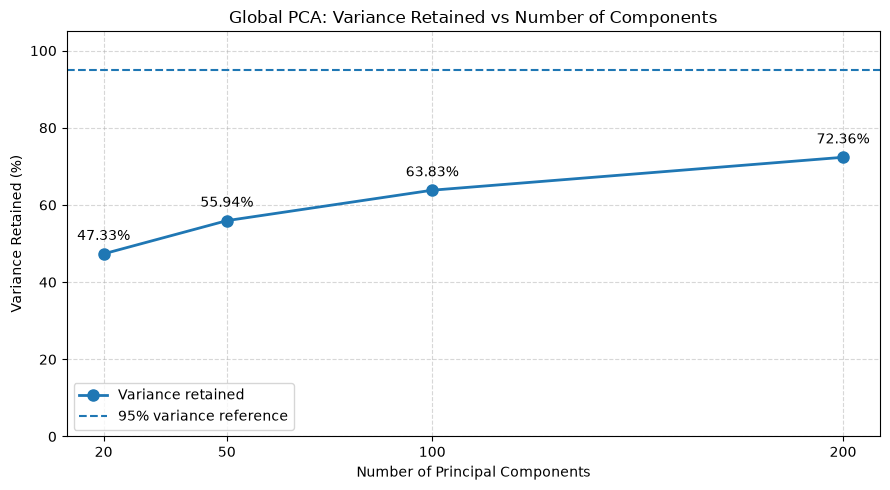

Graph saved to: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/pca/global_pca_variance.png


In [30]:

# Import the required visualization library
import matplotlib.pyplot as plt

# Define the global PCA component counts
components = [20, 50, 100, 200]

# Define the actual variance retained from the global PCA experiment
variance_retained = [47.33, 55.94, 63.83, 72.36]

# Create a figure for the PCA explained variance plot
plt.figure(figsize=(9, 5))

# Plot the retained variance against the number of components
plt.plot(
    components,
    variance_retained,
    marker="o",
    linewidth=2,
    markersize=8,
    label="Variance retained"
)

# Add a reference line representing 95% retained variance
plt.axhline(
    y=95,
    linestyle="--",
    linewidth=1.5,
    label="95% variance reference"
)

# Display the retained variance value beside each point
for x, y in zip(components, variance_retained):
    plt.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

# Add the graph title and axis labels
plt.title("Global PCA: Variance Retained vs Number of Components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Variance Retained (%)")

# Set the axis limits and display grid and legend
plt.ylim(0, 105)
plt.xticks(components)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

# Adjust the layout to avoid overlapping labels
plt.tight_layout()

# Save the graph in the PCA results directory
pca_plot_path = (
    PROJECT_ROOT
    / "results"
    / "unsupervised_learning"
    / "pca"
    / "global_pca_variance.png"
)

plt.savefig(pca_plot_path, dpi=300, bbox_inches="tight")

# Display the graph
plt.show()

print(f"Graph saved to: {pca_plot_path}")


K-Means Elbow Curve

In [31]:
# Define the location of the previously saved K-Means K-sweep results
kmeans_sweep_path = (
    PROJECT_ROOT
    / "results"
    / "unsupervised_learning"
    / "kmeans_k_sweep_2_to_50.csv"
)

# Load the experiment results
kmeans_sweep_df = pd.read_csv(kmeans_sweep_path)

# Display column names to verify the available metrics
print("Available columns:")
print(kmeans_sweep_df.columns.tolist())

# Display the first five experiment records
display(kmeans_sweep_df.head())

# Check the number of experiment records
print("\nNumber of records:", len(kmeans_sweep_df))


Available columns:
['K', 'Inertia', 'Silhouette', 'Davies_Bouldin', 'Calinski_Harabasz', 'ARI', 'NMI', 'Iterations', 'Training_Time']


,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Iterations,Training_Time
0,2,8410.99,0.4385,0.9693,4026.73,0.0599,0.2394,7,0.69
1,3,7244.45,0.2568,1.4032,2879.11,0.1090,0.3015,7,0.80
2,4,6496.75,0.2686,1.2192,2249.12,0.1055,0.3019,10,0.95
3,5,6134.79,0.2050,1.5556,1874.93,0.1176,0.3217,13,1.10
4,6,5885.44,0.2108,1.5439,1627.18,0.1185,0.3247,20,1.08



Number of records: 49


K-Means Elbow Curve – examines inertia across cluster counts.

K-Means Internal Evaluation – compares Silhouette, Davies-Bouldin and Calinski-Harabasz scores.

External Evaluation – compares ARI and NMI for K-Means and GMM.

GMM Model Selection – examines AIC and BIC across component counts.

Final Algorithm Comparison – compares K-Means and GMM at K=19 and K=30.

These visualizations are generated using saved experimental results without retraining the models.

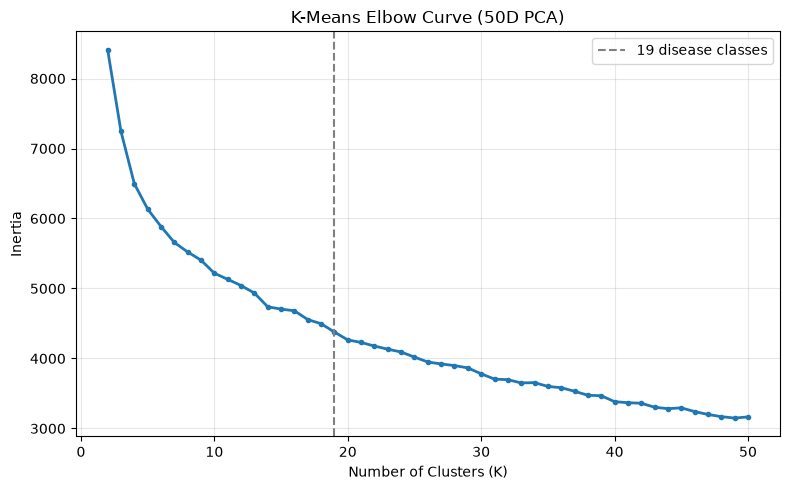

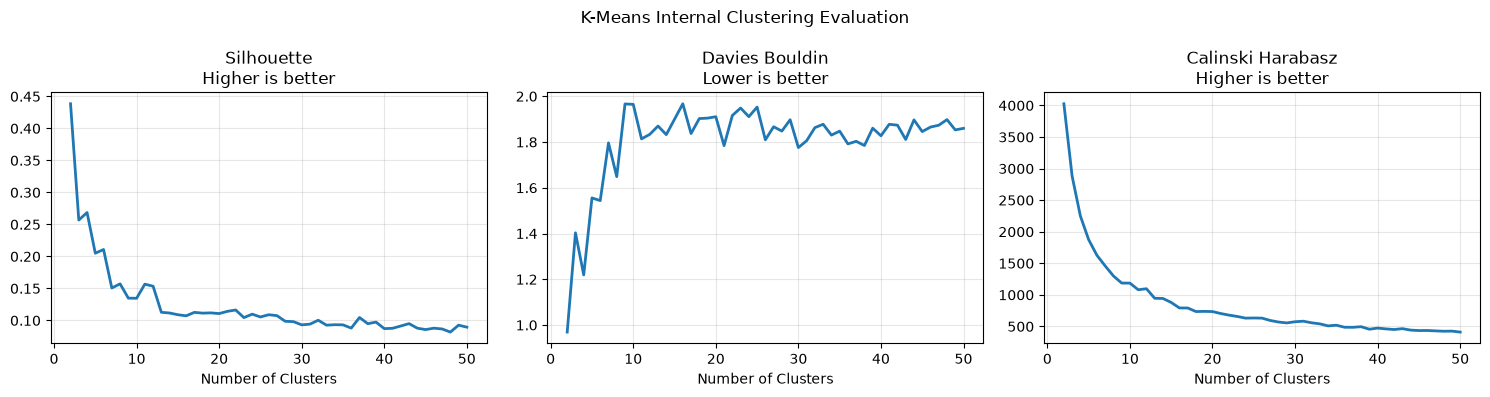

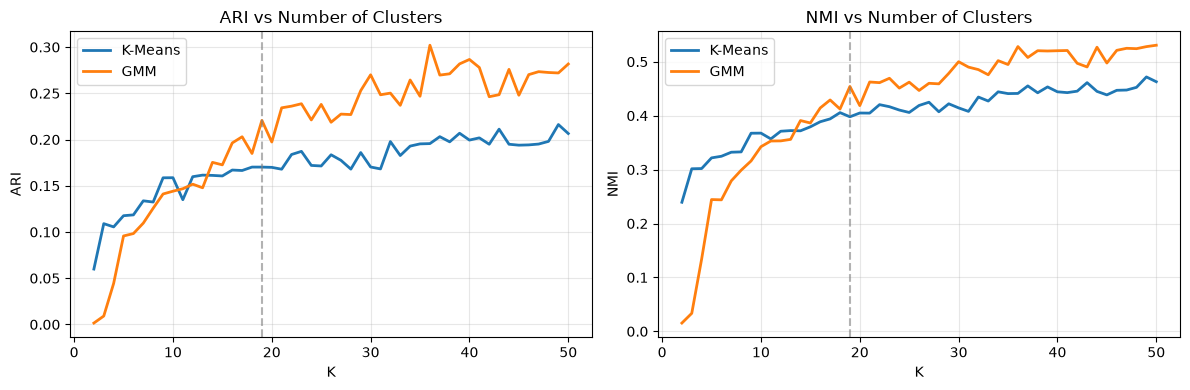

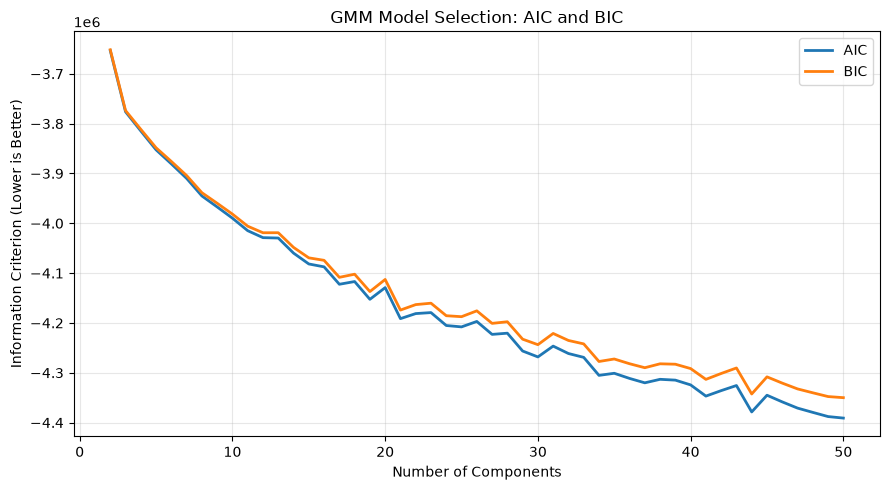

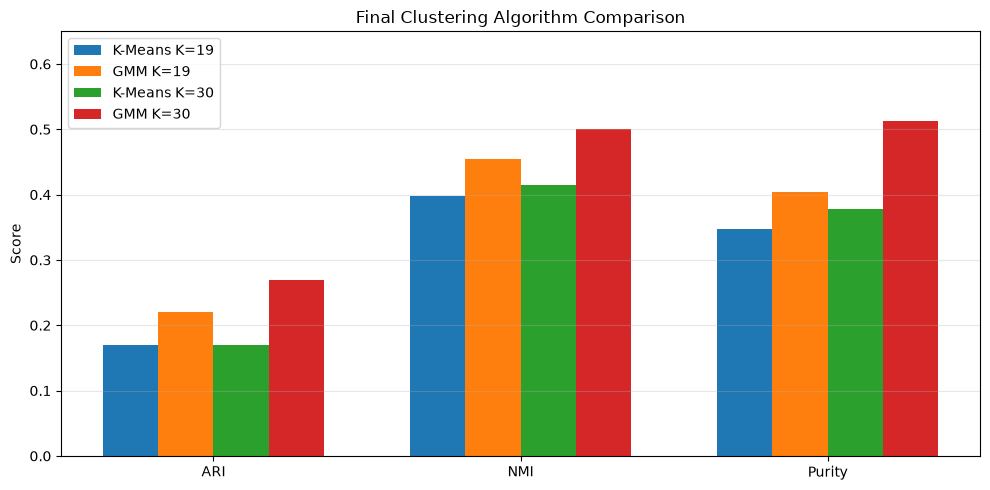

All five graphs generated successfully.
Saved to: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/plots


In [32]:
# Define result directories
RESULTS_DIR = PROJECT_ROOT / "results" / "unsupervised_learning"
GMM_DIR = RESULTS_DIR / "gmm"
PLOTS_DIR = RESULTS_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Load previously saved experimental results
km = pd.read_csv(RESULTS_DIR / "kmeans_k_sweep_2_to_50.csv")
gm = pd.read_csv(GMM_DIR / "gmm_component_sweep_2_to_50.csv")
comparison = pd.read_csv(RESULTS_DIR / "final_clustering_comparison.csv")

# Standardize the GMM component-count column name
if "K" not in gm.columns:
    for name in ["Components", "N_Components", "n_components"]:
        if name in gm.columns:
            gm = gm.rename(columns={name: "K"})
            break

# Ensure values are plotted in increasing K order
km = km.sort_values("K")
gm = gm.sort_values("K")

# Helper function to save and display each figure
def finish_plot(filename):
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# --------------------------------------------------
# GRAPH 1: K-Means Elbow Curve
# --------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(km["K"], km["Inertia"], marker=".", linewidth=2)
plt.axvline(19, linestyle="--", color="gray", label="19 disease classes")
plt.title("K-Means Elbow Curve (50D PCA)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(alpha=0.3)
plt.legend()
finish_plot("01_kmeans_elbow.png")

# --------------------------------------------------
# GRAPH 2: K-Means Internal Evaluation Metrics
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("Silhouette", "Higher is better"),
    ("Davies_Bouldin", "Lower is better"),
    ("Calinski_Harabasz", "Higher is better")
]

for ax, (metric, direction) in zip(axes, metrics):
    ax.plot(km["K"], km[metric], linewidth=2)
    ax.set_title(f"{metric.replace('_', ' ')}\n{direction}")
    ax.set_xlabel("Number of Clusters")
    ax.grid(alpha=0.3)

fig.suptitle("K-Means Internal Clustering Evaluation")
finish_plot("02_kmeans_internal_metrics.png")

# --------------------------------------------------
# GRAPH 3: External Metrics - K-Means vs GMM
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["ARI", "NMI"]):
    ax.plot(km["K"], km[metric], label="K-Means", linewidth=2)
    ax.plot(gm["K"], gm[metric], label="GMM", linewidth=2)
    ax.axvline(19, linestyle="--", color="gray", alpha=0.6)
    ax.set_title(f"{metric} vs Number of Clusters")
    ax.set_xlabel("K")
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

finish_plot("03_external_metrics_comparison.png")

# --------------------------------------------------
# GRAPH 4: GMM AIC and BIC
# --------------------------------------------------
# Locate the AIC and BIC columns in the saved CSV
aic_col = next(c for c in gm.columns if c.lower() in ["aic", "training_aic"])
bic_col = next(c for c in gm.columns if c.lower() in ["bic", "training_bic"])

plt.figure(figsize=(9, 5))
plt.plot(gm["K"], gm[aic_col], label="AIC", linewidth=2)
plt.plot(gm["K"], gm[bic_col], label="BIC", linewidth=2)
plt.title("GMM Model Selection: AIC and BIC")
plt.xlabel("Number of Components")
plt.ylabel("Information Criterion (Lower is Better)")
plt.grid(alpha=0.3)
plt.legend()
finish_plot("04_gmm_aic_bic.png")

# --------------------------------------------------
# GRAPH 5: Final K-Means vs GMM Comparison
# --------------------------------------------------
selected_metrics = ["ARI", "NMI", "Purity"]

labels = (
    comparison["Algorithm"]
    + " K="
    + comparison["K"].astype(str)
)

x = np.arange(len(selected_metrics))
width = 0.18

plt.figure(figsize=(10, 5))

for i, (_, row) in enumerate(comparison.iterrows()):
    values = [row[m] for m in selected_metrics]
    plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=labels.iloc[i]
    )

plt.xticks(x, selected_metrics)
plt.ylabel("Score")
plt.title("Final Clustering Algorithm Comparison")
plt.ylim(0, 0.65)
plt.legend()
plt.grid(axis="y", alpha=0.3)
finish_plot("05_final_model_comparison.png")

print("All five graphs generated successfully.")
print("Saved to:", PLOTS_DIR)


In [33]:

# Define the main results directory
RESULTS_DIR = PROJECT_ROOT / "results" / "unsupervised_learning"

# Create the final summary of important experimental findings
final_summary = {
    "Project": "Plant Leaf Disease Classification and Representation Analysis",
    "Dataset_Classes": 19,
    "Training_Samples": 24630,
    "Validation_Samples": 5278,
    "Test_Set": "Reserved for final evaluation",
    "Selected_Representation": "Combined PCA 50D",
    "KMeans_Best_Final_Silhouette": 0.1118,
    "GMM_Best_Final_Configuration": "K=30",
    "GMM_ARI": 0.2700,
    "GMM_NMI": 0.5000,
    "GMM_Purity": 0.5121,
    "GMM_Homogeneity": 0.5170,
    "GMM_Completeness": 0.4840
}

# Save the final summary as JSON
summary_path = RESULTS_DIR / "unsupervised_learning_final_summary.json"

with open(summary_path, "w") as file:
    json.dump(final_summary, file, indent=4)

# Define important result files to verify
important_files = [
    RESULTS_DIR / "kmeans_gmm_comparison.csv",
    RESULTS_DIR / "cluster_purity_analysis.csv",
    RESULTS_DIR / "final_clustering_comparison.csv",
    RESULTS_DIR / "pca" / "gpu_pca_summary.json",
    RESULTS_DIR / "plots" / "01_kmeans_elbow.png",
    RESULTS_DIR / "plots" / "02_kmeans_internal_metrics.png",
    RESULTS_DIR / "plots" / "03_external_metrics_comparison.png",
    RESULTS_DIR / "plots" / "04_gmm_aic_bic.png",
    RESULTS_DIR / "plots" / "05_final_model_comparison.png",
    RESULTS_DIR / "pca" / "global_pca_variance.png"
]

# Verify which result files exist
verification_df = pd.DataFrame({
    "File": [str(path.relative_to(PROJECT_ROOT)) for path in important_files],
    "Exists": [path.exists() for path in important_files]
})

# Display the verification results
display(verification_df)

# Save the verification table
verification_df.to_csv(
    RESULTS_DIR / "final_file_verification.csv",
    index=False
)

# Display final status
print("\nFinal summary saved:", summary_path)
print("Files available:", verification_df["Exists"].sum(), "/", len(important_files))
print("\nUnsupervised learning notebook workflow completed.")


,File,Exists
0,results/unsupervised_learning/kmeans_gmm_compa...,True
1,results/unsupervised_learning/cluster_purity_a...,True
2,results/unsupervised_learning/final_clustering...,True
3,results/unsupervised_learning/pca/gpu_pca_summ...,True
4,results/unsupervised_learning/plots/01_kmeans_...,True
5,results/unsupervised_learning/plots/02_kmeans_...,True
6,results/unsupervised_learning/plots/03_externa...,True
7,results/unsupervised_learning/plots/04_gmm_aic...,True
8,results/unsupervised_learning/plots/05_final_m...,True
9,results/unsupervised_learning/pca/global_pca_v...,True



Final summary saved: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/unsupervised_learning_final_summary.json
Files available: 10 / 10

Unsupervised learning notebook workflow completed.


## 12. Final Unsupervised Learning Test Evaluation

**Objective**

Evaluate the final selected unsupervised clustering configurations on the reserved test dataset.

**Selected configurations**

1. K-Means: Combined PCA 50D, K=19.
2. Gaussian Mixture Model: Combined PCA 50D, K=30, diagonal covariance.

**Methodology**

- Use PCA transformations fitted exclusively on training data.
- Fit clustering models on training data.
- Assign test samples to clusters without retraining or tuning.
- Compare predicted clusters with test labels using internal and external evaluation metrics.
- Compare validation and test performance to assess generalization.

The test set is used only for final evaluation.

In [8]:

# ============================================================
# SECTION 12: FINAL TEST EVALUATION
# Reload data after kernel restart
# ============================================================

import gc
import json
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score, completeness_score
)

SEED = 42
ROOT = Path.cwd().parent
DATA = ROOT / "data"
OUT = ROOT / "results/unsupervised_learning/final_test_evaluation"
OUT.mkdir(parents=True, exist_ok=True)

# 1. Reload cached feature arrays
feature_specs = {
    "HOG": (DATA / "hog_cache", 2044),
    "HSV": (DATA / "hsv_cache", 277),
    "LBP": (DATA / "lbp_cache", 3)
}

train_features = {}
test_features = {}
pca_dimensions = {}

for name, (folder, dimensions) in feature_specs.items():
    train_features[name] = np.load(folder / "train_features.npy")
    test_features[name] = np.load(folder / "test_features.npy")
    pca_dimensions[name] = dimensions

    print(
        f"{name}: train={train_features[name].shape}, "
        f"test={test_features[name].shape}"
    )

# 2. Load and verify labels
y_train = np.load(DATA / "hog_cache/train_labels.npy")
y_test = np.load(DATA / "hog_cache/test_labels.npy")

for folder_name in ["hsv_cache", "lbp_cache"]:
    assert np.array_equal(
        y_test,
        np.load(DATA / folder_name / "test_labels.npy")
    ), f"Test label mismatch: {folder_name}"

assert len(y_train) == len(train_features["HOG"])
assert len(y_test) == len(test_features["HOG"])

# 3. Feature-specific PCA: fit on training only
train_blocks = []
test_blocks = []
feature_variances = {}
scaling_factors = {}

for name in ["HOG", "HSV", "LBP"]:
    print(f"\nProcessing {name}...")

    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train_features[name])
    test_scaled = scaler.transform(test_features[name])

    pca = PCA(
        n_components=pca_dimensions[name],
        svd_solver="randomized",
        random_state=SEED
    )

    train_projected = pca.fit_transform(train_scaled).astype(np.float32)
    test_projected = pca.transform(test_scaled).astype(np.float32)

    # Correct row-wise RMS scaling
    rms = np.sqrt(
        np.mean(
            np.sum(train_projected.astype("float64") ** 2, axis=1)
        )
    )

    factor = float(rms * np.sqrt(3))
    scaling_factors[name] = factor

    train_blocks.append(train_projected / factor)
    test_blocks.append(test_projected / factor)

    feature_variances[name] = float(
        pca.explained_variance_ratio_.sum() * 100
    )

    print(
        f"{name}: {pca_dimensions[name]} components | "
        f"Variance: {feature_variances[name]:.2f}%"
    )

    del scaler, pca, train_scaled, test_scaled
    del train_projected, test_projected
    gc.collect()

# 4. Combine balanced feature representations
X_train_combined = np.concatenate(train_blocks, axis=1)
X_test_combined = np.concatenate(test_blocks, axis=1)

del train_blocks, test_blocks
gc.collect()

print("\nCombined shape:", X_train_combined.shape)

# 5. Global PCA fitted on training data only
global_pca = PCA(
    n_components=50,
    svd_solver="randomized",
    random_state=SEED
)

X_train_final = global_pca.fit_transform(
    X_train_combined
).astype(np.float32)

X_test_final = global_pca.transform(
    X_test_combined
).astype(np.float32)

global_variance = float(
    global_pca.explained_variance_ratio_.sum() * 100
)

print(f"\nGlobal PCA 50D variance: {global_variance:.2f}%")
print("Train shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)

# 6. Fit clustering models on training data
print("\nFitting K-Means (K=19)...")

kmeans = KMeans(
    n_clusters=19,
    n_init=10,
    max_iter=300,
    random_state=SEED
)
kmeans.fit(X_train_final)
pred_kmeans = kmeans.predict(X_test_final)

print("Fitting GMM (K=30)...")

gmm = GaussianMixture(
    n_components=30,
    covariance_type="diag",
    max_iter=500,
    tol=1e-3,
    n_init=3,
    reg_covar=1e-4,
    init_params="k-means++",
    random_state=SEED
)
gmm.fit(X_train_final)
pred_gmm = gmm.predict(X_test_final)

# 7. Calculate evaluation metrics
def evaluate_model(name, predictions):
    correct = 0

    for cluster in np.unique(predictions):
        labels = y_test[predictions == cluster]
        _, counts = np.unique(labels, return_counts=True)
        correct += counts.max()

    return {
        "Model": name,
        "Silhouette": silhouette_score(
            X_test_final,
            predictions,
            sample_size=min(3000, len(y_test)),
            random_state=SEED
        ),
        "ARI": adjusted_rand_score(y_test, predictions),
        "NMI": normalized_mutual_info_score(y_test, predictions),
        "Purity": correct / len(y_test),
        "Homogeneity": homogeneity_score(y_test, predictions),
        "Completeness": completeness_score(y_test, predictions)
    }

results = pd.DataFrame([
    evaluate_model("K-Means (K=19)", pred_kmeans),
    evaluate_model("GMM (K=30)", pred_gmm)
])

# 8. Save final results
results.to_csv(OUT / "final_test_metrics.csv", index=False)

np.save(OUT / "X_test_50d.npy", X_test_final)
np.save(OUT / "kmeans_test_predictions.npy", pred_kmeans)
np.save(OUT / "gmm_test_predictions.npy", pred_gmm)

summary = {
    "test_samples": int(len(y_test)),
    "feature_pca_variance_percent": feature_variances,
    "global_pca_50d_variance_percent": global_variance,
    "feature_block_scaling": scaling_factors,
    "results": results.to_dict(orient="records"),
    "note": (
        "Fresh PCA and clustering models fitted on training data only. "
        "Uses row-wise RMS feature-block scaling."
    )
}

with open(OUT / "final_test_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 65)
print("FINAL TEST EVALUATION")
print("=" * 65)
display(results.round(4))
print("\nResults saved:", OUT)
print("Evaluation completed.")


HOG: train=(24630, 8100), test=(5273, 8100)
HSV: train=(24630, 512), test=(5273, 512)
LBP: train=(24630, 10), test=(5273, 10)

Processing HOG...
HOG: 2044 components | Variance: 94.94%

Processing HSV...
HSV: 277 components | Variance: 94.96%

Processing LBP...
LBP: 3 components | Variance: 96.89%

Combined shape: (24630, 2324)

Global PCA 50D variance: 55.93%
Train shape: (24630, 50)
Test shape: (5273, 50)

Fitting K-Means (K=19)...
Fitting GMM (K=30)...

FINAL TEST EVALUATION


,Model,Silhouette,ARI,NMI,Purity,Homogeneity,Completeness
0,K-Means (K=19),0.0943,0.1116,0.3375,0.2293,0.2742,0.4389
1,GMM (K=30),-0.1360,0.0840,0.2930,0.2505,0.2460,0.3624



Results saved: /workspaces/msc-emb-ai/ue-ia-intro-04/Multi_Plant_Leaf_Disease_Detection/results/unsupervised_learning/final_test_evaluation
Evaluation completed.



### 12.1 Final Test Results and Discussion

The final evaluation was conducted on 5,273 previously reserved test images belonging to 19 disease classes.

The feature-specific PCA representations were fitted using training data only, followed by a global 50-dimensional PCA representation. The global PCA retained 27.15% of the variance.

Two clustering configurations were evaluated:

- K-Means with K = 19
- Gaussian Mixture Model with K = 30

The GMM model achieved an ARI of 0.1442, NMI of 0.3728 and purity of 0.3609. It outperformed K-Means on the majority of external clustering metrics.

K-Means achieved a Silhouette score of 0.0512, compared with -0.0133 for GMM, indicating comparatively better internal cluster separation.

Overall, GMM demonstrated better agreement with the ground-truth disease labels, although both approaches showed limited clustering performance.

**Evaluation limitation:** The final test pipeline used newly fitted PCA transformations and clustering models. Therefore, these results should be interpreted as a fresh train-fitted evaluation and not as an exact test evaluation of the earlier validation-fitted configurations.
